# SINASC 2014–2024 — auditoria empírica pré-V2 da temporalidade de MESPRENAT (09c)

> **Etapa diagnóstica e não causal.** Nenhuma estimativa AIPW, nenhum escore de propensão, nenhuma escolha de V2 e nenhuma alteração da V1.

> **Resumo.** Em 30.468.409 registros (2014–2024):
> 1. os meses 7–9 quase desaparecem nas gestações com menos de 27 semanas (≈0,03% dos meses conhecidos em 22–26 semanas, contra 2,0–3,5% a partir de 27) e a distribuição de `SEMAGESTAC` de cada mês acompanha a fronteira mecânica mês→semana;
> 2. **13,2%** do controle da V1 está nos meses 7–9 (12,4%–14,3% por ano, crescente desde 2020); **73,4%** em 4–5 e **86,8%** em 4–6;
> 3. B (4–6) reduz a fração de nascimentos estruturalmente afetados (M1, leitura L1) de 1,35% para 0,007%, e C (4–5) para praticamente zero, ao custo de 13,2% e 26,6% dos controles;
> 4. `CONSPRENAT=0` é definido oficialmente como "não fez pré-natal", mas vem acompanhado de `MESPRENAT` 99 ou vazio quase meio a meio, com categoria dominante que alterna entre anos e diverge da nacional em 113 de 261 UF-anos; `KOTELCHUCK=1` coincide 100% com `CONSPRENAT=0` e não traz informação independente;
> 5. `MESPRENAT` desconhecido caiu de 7,6% para 3,4%, é fortemente regional (RO e AC no topo em quase todos os anos) e diferencial em Y e X (BPN de 12,4% em 99 e 10,7% em vazio, contra 7,3% no mês conhecido);
> 6. só 38 de 27,9 milhões de registros têm mês de início potencialmente incompatível com a IG na leitura L1, além de 2.607 registros com o código `10` em 2014.
>
> **Gates:** G1 `SINALIZADO` · G2 `SINALIZADO` · G3 `SINALIZADO` · G4 `SINALIZADO` · G5 `APROVADO` · G6 `APROVADO` · G7 `SINALIZADO`. B e C podem seguir para **discussão metodológica com ressalvas**; D (*landmark*) permanece `PENDENTE`. `NENHUMA_NOVA_ESTIMATIVA_CAUSAL` · `V1_PRESERVADA` · `V2_NAO_ESCOLHIDA`.

## 1. Contexto e escopo

A **V1** permanece integral e válida como contraste observacional padronizado na população selecionada: `T=1` se `MESPRENAT ∈ {1,2,3}`, `T=0` se `MESPRENAT ∈ {4,…,9}`, desfecho baixo peso ao nascer (`PESO < 2.500 g`), janela 2014–2024, AIPW com ajuste cruzado. Ela **não** é promovida aqui a efeito de uma intervenção bem definida de início precoce.

A ameaça investigada é estrutural: para pertencer, por exemplo, a `MESPRENAT=7`, a gestação precisa durar o suficiente para que a mulher chegue ao 7º mês antes de iniciar o pré-natal. Trata-se de um **viés temporal do tipo *immortal time*, gerado por classificação e seleção baseadas em informação posterior ao tempo zero**, e, no desfecho baixo peso, de um **viés de duração da gestação (*preterm delivery bias* / *gestational age bias*)**. Não se trata do *immortal time* clássico de análise de sobrevivência. Na literatura fichada, Vachuska (2025, p. 3) descreve que o início tardio é mecanicamente associado a menos prematuridade, e o baixo peso tem o mesmo problema.

Formulações apenas **descritas** nesta rodada (nenhuma é estimada nem escolhida):

| Código | Tratado | Controle | Situação |
| --- | --- | --- | --- |
| A (V1) | meses 1–3 | meses 4–9 | preservada |
| B | meses 1–3 | meses 4–6 | sensibilidade candidata |
| C | meses 1–3 | meses 4–5 | sensibilidade candidata |
| D (*landmark*) | iniciou até o fim do 3º mês | ainda não iniciou nesse momento | bloqueada/pendente: exige distinguir "nunca iniciou" de "início desconhecido" |

Idade gestacional (`SEMAGESTAC`, `GESTACAO`) é usada **somente** como variável diagnóstica da estrutura temporal da exposição. Não entra em X, não restringe a amostra e não define desfecho.

In [1]:
from pathlib import Path
import hashlib
import json
import subprocess
import sys
import time
from datetime import datetime

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.colors import sample_colorscale
from plotly.subplots import make_subplots
from IPython.display import Image, Markdown, display

raiz = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / 'src').exists()).resolve()
sys.path.insert(0, str(raiz))
assert Path(sys.executable).resolve() == (raiz / '.venv/Scripts/python.exe').resolve(), 'Use a .venv do projeto'

from src import auditoria_pre_v2 as ap
from src import temporal as tp
from src.visualizacao import configurar_plotly, aplicar_tema_ipt, CORES_IPT

configurar_plotly()
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 220)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

INICIO_NOTEBOOK = time.perf_counter()
pasta = raiz / 'outputs/temporal/pre_v2'
pasta_fig = pasta / 'figuras'
pasta_fig.mkdir(parents=True, exist_ok=True)
tempos_diag = {}
saidas = {}

class cronometro:
    # Acumula o tempo de pós-processamento (pandas) por diagnóstico.
    def __init__(self, nome):
        self.nome = nome
    def __enter__(self):
        self.inicio = time.perf_counter()
    def __exit__(self, *erro):
        tempos_diag[self.nome] = tempos_diag.get(self.nome, 0.0) + time.perf_counter() - self.inicio

def salvar(tabela, nome, descricao, granularidade, chave):
    caminho = pasta / f'{nome}.csv'
    ap.salvar_csv(tabela, caminho)
    saidas[caminho.name] = {'descricao': descricao, 'granularidade': granularidade, 'chave': chave,
                            'linhas': int(len(tabela))}

def mostrar(fig, titulo, nome, altura=560, largura=1100):
    aplicar_tema_ipt(fig, titulo)
    fig.update_layout(width=largura, height=altura, margin=dict(l=90, r=50, t=100, b=90), separators=',.')
    fig.update_xaxes(automargin=True)
    fig.update_yaxes(automargin=True)
    caminho = pasta_fig / f'{nome}.png'
    fig.write_image(caminho, scale=1.5)
    saidas[f'figuras/{caminho.name}'] = {'descricao': titulo, 'granularidade': 'figura', 'chave': '-', 'linhas': 0}
    display(Image(filename=str(caminho)))

UF_SIGLA = {'11': 'RO', '12': 'AC', '13': 'AM', '14': 'RR', '15': 'PA', '16': 'AP', '17': 'TO',
            '21': 'MA', '22': 'PI', '23': 'CE', '24': 'RN', '25': 'PB', '26': 'PE', '27': 'AL',
            '28': 'SE', '29': 'BA', '31': 'MG', '32': 'ES', '33': 'RJ', '35': 'SP', '41': 'PR',
            '42': 'SC', '43': 'RS', '50': 'MS', '51': 'MT', '52': 'GO', '53': 'DF', 'IGNORADO': 'IGN'}
ROTULO_GRUPO = {'1-3': 'Mês 1–3', '4-5': 'Mês 4–5', '6': 'Mês 6', '7-9': 'Mês 7–9'}
COR_GRUPO = {'1-3': CORES_IPT['AZUL_ESCURO'], '4-5': CORES_IPT['AZUL_MEDIO'], '6': CORES_IPT['AZUL_CLARO'],
             '7-9': '#D9822B'}
ROTULO_ALT = {'A_V1_4_9': 'A (V1): 4–9', 'B_4_6': 'B: 4–6', 'C_4_5': 'C: 4–5'}
ANOS = list(ap.ANOS_AUDITORIA)
print('Anos:', ANOS[0], '–', ANOS[-1], '| versão:', ap.VERSAO_AUDITORIA)

Anos: 2014 – 2024 | versão: pre-v2-1 (critérios fixados em 2026-10-01 antes das agregações D1-D8)


### 1.1 Estado inicial e arquivos reservados

Registra HEAD, `git status` e impressões digitais dos arquivos reservados (frente do Codex 09/09b, estimativas AIPW, caches, notebooks 01–09, gate histórico). SHA-256 para arquivos pequenos; tamanho e data de modificação para caches em `data/interim/`. Ao final, as mesmas impressões são comparadas.

In [2]:
def git(*args):
    return subprocess.run(['git', *args], cwd=raiz, capture_output=True, text=True, check=True).stdout

def impressoes_reservadas():
    alvos = [raiz / 'notebooks' / n for n in sorted(p.name for p in (raiz / 'notebooks').glob('0*.ipynb'))
             if not n.startswith('09c')]
    alvos += [raiz / 'src/estimativas_temporais.py', raiz / 'tests/test_estimativas_temporais.py',
              raiz / 'src/temporal.py', raiz / 'src/amostra.py', raiz / 'outputs/diagnostics/fase3_gate.json',
              raiz / 'requirements_before_spark.txt']
    alvos += sorted((raiz / 'outputs/temporal/estimativas').glob('*'))
    alvos += sorted((raiz / 'outputs/temporal/figuras').glob('*'))
    alvos += sorted((raiz / 'docs/literature/pdfs').glob('*'))
    impressoes = {p.relative_to(raiz).as_posix(): ap.sha256_arquivo(p) for p in alvos if p.is_file()}
    for pasta_cache in ('data/interim/estimativas_temporais', 'data/interim/temporal_overlap',
                        'data/interim/nuisance_benchmark'):
        for p in sorted((raiz / pasta_cache).rglob('*')):
            if p.is_file():
                s = p.stat()
                impressoes[p.relative_to(raiz).as_posix()] = f'{s.st_size}:{s.st_mtime_ns}'
    return impressoes

git_head = git('rev-parse', 'HEAD').strip()
git_branch = git('rev-parse', '--abbrev-ref', 'HEAD').strip()
git_status_inicio = git('status', '--short', '--untracked-files=all')
reservados_inicio = impressoes_reservadas()
print('Branch:', git_branch, '| HEAD:', git_head)
print('Arquivos reservados monitorados:', len(reservados_inicio))
print(git_status_inicio)

Branch: feature/expansao-temporal-sinasc | HEAD: 61efda505592ed80a352322b3dee9d80f894f6ef
Arquivos reservados monitorados: 801
 M outputs/diagnostics/fase3_gate.json
?? docs/literature/pdfs/chernozhukov2018.pdf
?? docs/literature/pdfs/chernozhukov2018.txt
?? docs/literature/pdfs/chiang2022.pdf
?? docs/literature/pdfs/chiang2022.txt
?? docs/literature/pdfs/falcao2020.pdf
?? docs/literature/pdfs/falcao2020.txt
?? docs/literature/pdfs/kennedy2023.pdf
?? docs/literature/pdfs/kennedy2023.txt
?? docs/literature/pdfs/ranjbar2023.pdf
?? docs/literature/pdfs/ranjbar2023.txt
?? notebooks/09_estabilidade_temporal_estimativas.ipynb
?? notebooks/09b_auditoria_inferencia_temporal.ipynb
?? notebooks/09c_auditoria_pre_v2_temporalidade_exposicao.ipynb
?? outputs/temporal/estimativas/ano_2014.json
?? outputs/temporal/estimativas/ano_2015.json
?? outputs/temporal/estimativas/ano_2016.json
?? outputs/temporal/estimativas/ano_2017.json
?? outputs/temporal/estimativas/ano_2018.json
?? outputs/temporal/estim

## 2. Inventário do schema 2014–2024

Leitura apenas dos metadados Parquet e dos **domínios** (valores distintos, sem frequências) dos campos codificados. Nomes são comparados sem diferenciar caixa (2016 usa minúsculas; DuckDB resolve identificadores sem diferenciar caixa). Os caminhos vêm de `src.temporal.caminhos_ano`, a mesma harmonização usada desde o notebook 06.

In [3]:
caminhos = {ano: tp.caminhos_ano(raiz, ano).parquet for ano in ANOS}
schema = pd.concat([ap.inventario_schema(caminhos[a], a) for a in ANOS], ignore_index=True)
dominios = pd.concat([ap.dominios_codigos(caminhos[a], a) for a in ANOS], ignore_index=True)
salvar(schema, 'schema_pre_v2', 'Presença, nome original, caixa e tipo dos campos por ano', 'ano x campo', 'ano, campo')
salvar(dominios, 'dominios_codigos_pre_v2', 'Códigos distintos observados (sem frequências)', 'ano x campo', 'ano, campo')

presenca = schema.pivot(index='campo', columns='ano', values='presente')
display(presenca.replace({True: 'sim', False: 'NÃO'}))
print('Campos com caixa diferente:', schema.loc[schema.caixa_diferente].groupby('ano').campo.apply(len).to_dict())
print('Tipos Parquet:', schema.tipo_parquet.dropna().unique().tolist())
display(dominios.pivot(index='ano', columns='campo', values='codigos_distintos'))
n_bruto = schema.groupby('ano').n_registros.first()
print('Registros brutos por ano:', n_bruto.to_dict(), '| total:', f'{n_bruto.sum():,}')
assert schema.loc[schema.campo.isin(ap.COLUNAS_LIDAS), 'presente'].all(), 'Campo necessário ausente'

ano,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
campo,,,,,,,,,,,
CODMUNRES,sim,sim,sim,sim,sim,sim,sim,sim,sim,sim,sim
CONSPRENAT,sim,sim,sim,sim,sim,sim,sim,sim,sim,sim,sim
CONSULTAS,sim,sim,sim,sim,sim,sim,sim,sim,sim,sim,sim
CONTADOR,sim,sim,sim,sim,sim,sim,sim,sim,sim,sim,sim
DTNASC,sim,sim,sim,sim,sim,sim,sim,sim,sim,sim,sim
DTULTMENST,sim,sim,sim,sim,sim,sim,sim,sim,sim,sim,sim
ESCMAE2010,sim,sim,sim,sim,sim,sim,sim,sim,sim,sim,sim
ESTCIVMAE,sim,sim,sim,sim,sim,sim,sim,sim,sim,sim,sim
GESTACAO,sim,sim,sim,sim,sim,sim,sim,sim,sim,sim,sim


Campos com caixa diferente: {2016: 21, 2023: 1, 2024: 1}
Tipos Parquet: ['large_string']


campo,CONSULTAS,GESTACAO,KOTELCHUCK,MESPRENAT,TPMETESTIM
ano,,,,,
2014,1|2|3|4|9|<NULL>,1|2|3|4|5|6|9|<NULL>,1|2|3|4|5|9,01|02|03|04|05|06|07|08|09|10|99|<NULL>,1|2|8|9|<NULL>
2015,1|2|3|4|9|<NULL>,1|2|3|4|5|6|9|<NULL>,1|2|3|4|5|9,01|02|03|04|05|06|07|08|09|99|<NULL>,1|2|8|9|<NULL>
2016,1|2|3|4|9|<NULL>,1|2|3|4|5|6|9|<NULL>,1|2|3|4|5|9,01|02|03|04|05|06|07|08|09|99|<NULL>,1|2|8|9|<NULL>
2017,1|2|3|4|9|<NULL>,1|2|3|4|5|6|9|<NULL>,1|2|3|4|5|9,01|02|03|04|05|06|07|08|09|99|<NULL>,1|2|8|9|<NULL>
2018,1|2|3|4|9|<NULL>,1|2|3|4|5|6|9|<NULL>,1|2|3|4|5|9,01|02|03|04|05|06|07|08|09|99|<NULL>,1|2|8|9|<NULL>
2019,1|2|3|4|9|<NULL>,1|2|3|4|5|6|9|<NULL>,1|2|3|4|5|9,01|02|03|04|05|06|07|08|09|99|<NULL>,1|2|8|9|<NULL>
2020,1|2|3|4|9|<NULL>,1|2|3|4|5|6|9|<NULL>,1|2|3|4|5|9,01|02|03|04|05|06|07|08|09|99|<NULL>,1|2|8|9|<NULL>
2021,1|2|3|4|9|<NULL>,1|2|3|4|5|6|9|<NULL>,1|2|3|4|5|9,01|02|03|04|05|06|07|08|09|99|<NULL>,1|2|8|9|<NULL>
2022,1|2|3|4|9|<NULL>,1|2|3|4|5|6|9|<NULL>,1|2|3|4|5|9,01|02|03|04|05|06|07|08|09|99|<NULL>,1|2|8|9|<NULL>


Registros brutos por ano: {2014: 2979259, 2015: 3017668, 2016: 2857800, 2017: 2923535, 2018: 2944932, 2019: 2849146, 2020: 2730145, 2021: 2677101, 2022: 2561922, 2023: 2537576, 2024: 2389325} | total: 30,468,409


**Leitura.** Todos os 21 campos inventariados existem nos 11 anos, sempre como texto. 2016 usa nomes em minúsculas (21 dos campos inventariados) e 2023–2024 trazem `contador` em minúsculas; a leitura por DuckDB e a normalização de `src.temporal` absorvem isso sem mapeamento adicional. Os domínios codificados são estáveis: `MESPRENAT` `01`–`09`, `99` e nulo em todos os anos, com `10` apenas em 2014; `KOTELCHUCK` `1`–`5` e `9`, sem nulos; `TPMETESTIM` `1`, `2`, `8`, `9` e nulo; `GESTACAO` `1`–`6`, `9` e nulo; `SEMAGESTAC` entre 15 (só 2014) ou 19 e 45–46 semanas, sem código de ignorado. No Parquet, o "vazio" de `MESPRENAT` aparece como nulo; não há string vazia.

## 3. Evidência documental

Distinção preservada: **completude** (preenchido ou não), **consistência** (coerência com outros campos) e **validade** (concordância com padrão-ouro). Os dados desta auditoria avaliam completude e consistência; **não demonstram validade**. Não foi localizado estudo pós-2011 que valide diretamente `MESPRENAT` da DN contra padrão-ouro; Szwarcwald et al. (2019, p. 10) relatam 41% sem informação do trimestre de início no SINASC 2011–2012 (completude, não validade). Ausência de validação não é prova de invalidade.

| Fonte | O que diz (literal ou resumo fiel) | Uso aqui |
| --- | --- | --- |
| *SINASC: Estrutura de 1996 a 2019* (MS/SVS/CGIAE), `data/raw/SINASC_Estrutura.pdf` | `MESPRENAT`: "Mês de gestação em que iniciou o pré‐natal" (desde 2010), **sem lista de códigos**; `SEMAGESTAC`: "Número de semanas de gestação"; `TPMETESTIM`: "1– Exame físico; 2– Outro método; 9– Ignorado"; `GESTACAO`: "1– Menos de 22 semanas; 2– 22 a 27; 3– 28 a 31; 4– 32 a 36; 5– 37 a 41; 6– 42 e mais; 9– Ignorado"; `KOTELCHUCK`: "índice de Kotelchuck - Avaliação da assistência pré-natal" (desde 2014), **sem códigos** | semântica dos campos |
| *Declaração de Nascido Vivo: manual de instruções para preenchimento*, 4ª ed., MS/SVS, 2022, p. 31–32 (impressas) | campo 33: "Caso não se conheça o dado, preencher 'Ignorado'. Colocar '0' caso a(o) parturiente não tenha feito pré-natal."; campo 34: "preencher com numeração em forma ordinal: 2o, 3o, 4o etc., correspondendo ao mês da gestação em que houve a primeira consulta de pré-natal. Caso não se conheça o dado, preencher 'Ignorado'."; campo 32 (p. 31): semanas "só é necessário quando a DUM for ignorada" | semântica de `CONSPRENAT=0` e da categoria Ignorado |
| mesmo manual, p. 79 (impressa), caso clínico do campo 34 | "OBS.: não existe início de pré-natal no 10º mês." | `MESPRENAT=10` fora do domínio oficial |

**Sobre `MESPRENAT=99`.** O texto do Manual 2022 não contém o número `99` em nenhuma página (busca no PDF oficial, acesso em 2026-10-01). O manual define a categoria "Ignorado", mas não seu código numérico no arquivo. Portanto `99` é rotulado `CODIFICACAO_OPERACIONAL_OBSERVADA`, não `DEFINICAO_OFICIAL`. O mesmo vale para `CONSPRENAT=99`. Esta leitura diverge da redação de `docs/sources/FONTES_OFICIAIS.md`, que atribui ao formulário o código 99; o documento não é alterado nesta rodada, e a divergência é registrada no relatório.

**Sobre `KOTELCHUCK`.** A documentação oficial localizada define apenas o nome do índice. Os códigos observados (`1`–`5`, `9`) e a existência de uma categoria "sem pré-natal" **não foram confirmados documentalmente**: o TabNet federal recusou conexão, o TabNet estadual do ES falhou na verificação de certificado, e a nota técnica SINASC de Campinas e o dicionário de microdados da SES-ES (consultados em 2026-10-01) não listam os códigos. A descrição do D8 é, portanto, puramente empírica.

**Sobre `TPMETESTIM=8`.** O código `8` aparece em todos os anos e não consta do dicionário nem do manual; fica como `CODIFICACAO_OPERACIONAL_OBSERVADA`, sem interpretação.

In [4]:
fontes_documentais = [
    {'fonte': 'SINASC: Estrutura de 1996 a 2019 - Dicionário de Dados (MS/SVS/CGIAE)',
     'url': 'https://diaad.s3.sa-east-1.amazonaws.com/sinasc/SINASC+-+Estrutura.pdf',
     'local': 'data/raw/SINASC_Estrutura.pdf', 'acesso': '2026-09-25 (projeto)'},
    {'fonte': 'Declaração de Nascido Vivo: manual de instruções para preenchimento, 4ª ed., MS, 2022',
     'url': 'https://svs.aids.gov.br/daent/cgiae/coesv/sistemas-informacao/sinasc/documentacao/declaracao-nascido-vivo-manual-instrucoes-preenchimento.pdf',
     'local': 'não versionado (cópia temporária fora do repositório)',
     'sha256_copia_consultada': '5956ea4d8e89ee6c3720b9769c83be09e6017cf2d1c3aa18a55898ee32e4deaf',
     'acesso': '2026-10-01', 'trechos': 'p. 31-32 (campos 32-34) e p. 79 (caso clínico do campo 34)'},
    {'fonte': 'SINASC - Notas técnicas, Secretaria Municipal de Saúde de Campinas',
     'url': 'https://portal-adm.campinas.sp.gov.br/sites/default/files/secretarias/arquivos-avulsos/125/2026/05/13-093624/NT_SINASC.pdf',
     'acesso': '2026-10-01', 'resultado': 'sem definição de KOTELCHUCK'},
    {'fonte': 'Dicionário de dados SINASC, SES-ES',
     'url': 'https://app.wiki.saude.es.gov.br/vigilancia/microdados/dicionario-de-dados_sinasc.pdf',
     'acesso': '2026-10-01', 'resultado': 'sem códigos de KOTELCHUCK; MESPRENAT sem lista de códigos'},
    {'fonte': 'TabNet DATASUS - notas técnicas SINASC', 'url': 'http://tabnet.datasus.gov.br/cgi/sinasc/nvdescr.htm',
     'acesso': '2026-10-01', 'resultado': 'conexão recusada; não consultado'},
]
semantica = pd.DataFrame([
    {'codigo': 'CONSPRENAT=0', 'rotulo': 'DEFINICAO_OFICIAL', 'semantica': 'não fez pré-natal (Manual 2022, campo 33)'},
    {'codigo': 'CONSPRENAT=99', 'rotulo': ap.ROTULO_99_CONSPRENAT, 'semantica': 'provável Ignorado; código numérico não documentado'},
    {'codigo': 'MESPRENAT=99', 'rotulo': ap.ROTULO_99_MESPRENAT, 'semantica': 'provável Ignorado; código numérico não documentado'},
    {'codigo': 'MESPRENAT vazio', 'rotulo': 'SEM_SEMANTICA_OFICIAL', 'semantica': 'não preenchido; sem regra no manual'},
    {'codigo': 'MESPRENAT=10', 'rotulo': 'FORA_DO_DOMINIO_OFICIAL', 'semantica': 'Manual 2022: não existe início no 10º mês'},
    {'codigo': 'TPMETESTIM=8', 'rotulo': 'CODIFICACAO_OPERACIONAL_OBSERVADA', 'semantica': 'não documentado'},
    {'codigo': 'KOTELCHUCK 1-5, 9', 'rotulo': 'NAO_CONFIRMADO_DOCUMENTALMENTE', 'semantica': 'índice de Kotelchuck; códigos sem fonte oficial localizada'},
])
salvar(semantica, 'semantica_codigos_pre_v2', 'Procedência semântica dos códigos usados', 'código', 'codigo')
display(semantica)

,codigo,rotulo,semantica
0,CONSPRENAT=0,DEFINICAO_OFICIAL,"não fez pré-natal (Manual 2022, campo 33)"
1,CONSPRENAT=99,CODIFICACAO_OPERACIONAL_OBSERVADA,provável Ignorado; código numérico não documen...
2,MESPRENAT=99,CODIFICACAO_OPERACIONAL_OBSERVADA,provável Ignorado; código numérico não documen...
3,MESPRENAT vazio,SEM_SEMANTICA_OFICIAL,não preenchido; sem regra no manual
4,MESPRENAT=10,FORA_DO_DOMINIO_OFICIAL,Manual 2022: não existe início no 10º mês
5,TPMETESTIM=8,CODIFICACAO_OPERACIONAL_OBSERVADA,não documentado
6,"KOTELCHUCK 1-5, 9",NAO_CONFIRMADO_DOCUMENTALMENTE,índice de Kotelchuck; códigos sem fonte oficia...


## 4. Pré-registro dos diagnósticos D1–D8

Escrito **antes** de qualquer agregação nacional desta rodada. Nada é excluído, imputado ou reclassificado; `99`, vazio e outros inválidos nunca entram em `T`. Populações usadas:

- **BRUTA**: todos os registros do arquivo anual;
- **ELEGIVEL**: gestação única (`GRAVIDEZ=1`) e `PESO` entre 500 e 6.000 g — a elegibilidade da V1 sem a condição sobre `T`;
- **V1**: ELEGIVEL com `MESPRENAT` 01–09 (população principal da V1; conferida contra `outputs/temporal/tabelas/tratamento_anual.csv`).

### D1 — idade gestacional × MESPRENAT
- **Pergunta:** como a distribuição do mês de início varia com a duração da gestação?
- **Hipótese:** se houver truncamento estrutural, meses 07–09 rareiam progressivamente nas faixas mais curtas.
- **Pode demonstrar:** o padrão empírico de coocorrência mês × duração, compatível ou não com truncamento.
- **Não pode demonstrar:** a causa do padrão (truncamento e perfil de risco de quem inicia tarde se confundem), a validade de `SEMAGESTAC`, nem qualquer efeito.
- **Regra:** população ELEGIVEL; faixas `<22`, `22–26`, `27–31`, `32–36`, `37–41`, `>=42`, ausente/inválida (`SEMAGESTAC` inteira em 0–98 é válida; nenhum filtro de plausibilidade). N, proporção dentro do estrato de IG e dentro do mês; Brasil, ano e UF. `GESTACAO` oficial cruzada em paralelo. Evidência auxiliar P1: proporção de 07–09 entre meses conhecidos não decrescente de `<22` a `37–41`, por ano.
- **Limitações:** faixas descritivas, não meses gestacionais oficiais; `SEMAGESTAC` pode vir da DUM ou de estimativa; concordância moderada da IG no SINASC (kappa 0,461; Szwarcwald 2019); somente nascidos vivos.

### D2 — consistência MESPRENAT × SEMAGESTAC
- **Pergunta:** há combinações temporalmente implausíveis?
- **Hipótese:** registros com mês de início posterior à duração da gestação existirão em pequena quantidade (erro de registro ou datação).
- **Pode demonstrar:** a frequência de combinações potencialmente incompatíveis sob leituras explícitas.
- **Não pode demonstrar:** impossibilidade (não há regra oficial mês→semana), nem qual dos dois campos está errado.
- **Regra:** população ELEGIVEL, meses 01–09, `SEMAGESTAC` válida. `S` semanas completas ⇒ duração em `[S, S+1)`. Mês `k` potencialmente incompatível se `S+1 ≤ início(k)`. L1: `4(k−1)`; L2: `4,345(k−1)`; L1 com tolerância: `4(k−2)`. Status: `POTENCIALMENTE_INCOMPATIVEL_MESMO_COM_TOLERANCIA`, `POTENCIALMENTE_INCOMPATIVEL_L1`, `POTENCIALMENTE_INCOMPATIVEL_SOMENTE_L2`, `SEM_INCOMPATIBILIDADE_DETECTADA`. Nada é chamado de impossível; nenhum registro é excluído.
- **Limitações:** as leituras são convenções transparentes; mês de início é retrospectivo; `SEMAGESTAC` tem erro.

### D3 — CONSPRENAT=0 × MESPRENAT
- **Pergunta:** a ausência de pré-natal tem codificação estável o suficiente para um *landmark*?
- **Hipótese:** se `CONSPRENAT=0` for usado coerentemente, os registros com zero consultas terão `MESPRENAT` predominantemente 99/vazio, de forma estável entre anos e UFs.
- **Pode demonstrar:** coerência e estabilidade da codificação conjunta.
- **Não pode demonstrar:** que zero consultas significa ausência real de pré-natal (validade).
- **Regra:** grupos de `MESPRENAT` `1–3`, `4–5`, `6`, `7–9`, `99`, `VAZIO`, `OUTRO_INVALIDO`; categorias de `CONSPRENAT` `0`, `01–03`, `04–06`, `07–98`, `99`, `VAZIO`, `OUTRO_INVALIDO`. Populações BRUTA e ELEGIVEL; Brasil × ano e UF × ano; N, proporções e três denominadores (total, dentro de `CONSPRENAT`, dentro do grupo de `MESPRENAT`). Nenhum código vira "nunca iniciou".
- **Limitações:** `CONSPRENAT=99` sem semântica oficial numérica; UFs pequenas têm células pequenas.

### D4 — perfil dos MESPRENAT desconhecidos (DESCRITIVO / NÃO CAUSAL)
- **Pergunta:** quem tem mês desconhecido difere de quem tem mês conhecido?
- **Hipótese:** o desconhecido concentra-se em perfis e UFs específicos (ausência não aleatória).
- **Pode demonstrar:** diferenças descritivas de Y, X, IG e UF entre grupos.
- **Não pode demonstrar:** o mês verdadeiro dos desconhecidos, o mecanismo do missing, nem viés da V1 em sentido causal.
- **Regra:** população ELEGIVEL; grupos CONHECIDO, `99`, `VAZIO`, `OUTRO_INVALIDO` (este só em anos com N ≥ 100). Variáveis: BPN, IG (faixas), idade materna, escolaridade, raça/cor, situação conjugal, paridade, perdas fetais (`QTDFILMORT`), UF. SMD por nível contra CONHECIDO, rotulada **diagnóstico de seleção/missingness, não balanceamento causal**. Sem imputação.
- **Limitações:** proporções brutas; diferenças regionais dominam vários contrastes.

### D5 — missing de MESPRENAT por ano × UF
- **Pergunta:** a ausência do mês varia no tempo e entre UFs?
- **Hipótese:** heterogeneidade regional relevante e possível mudança temporal.
- **Pode demonstrar:** tendência e heterogeneidade descritivas, separando 99, vazio e outros inválidos.
- **Não pode demonstrar:** causas (processos locais de coleta, digitação, sistema).
- **Regra:** populações BRUTA e ELEGIVEL; N, denominador e proporção. Triagem descritiva fixada antes: UF-ano com ≥ 100 registros e proporção de desconhecido ≥ 2× a nacional do mesmo ano é listada como "discrepante" apenas para leitura. Nenhuma UF é removida.
- **Limitações:** a triagem é convenção sem base científica e não decide nada.

### D6 — heaping / distribuição de MESPRENAT
- **Pergunta:** há acúmulo em meses específicos, sobretudo 2, 3 e na fronteira 3/4?
- **Hipótese:** pode haver preferência por meses redondos ou pela fronteira do 1º trimestre.
- **Pode demonstrar:** irregularidades descritivas na distribuição 1–9.
- **Não pode demonstrar:** manipulação, causalidade ou o mês verdadeiro. Uma descontinuidade 3/4 não é interpretada como efeito.
- **Regra:** Brasil × ano × mês e UF × ano × mês (BRUTA e ELEGIVEL). Indicadores fixados antes: `p_mes`, razão 3/4, razão 2/3, vizinhança do 3 = `n3 / ((n2+n4)/2)`, vizinhança do 2 = `n2 / ((n1+n3)/2)`, salto 3/4 em pp. Processo de mensuração: mesmos indicadores por presença de `DTULTMENST` e por `TPMETESTIM` (somente diagnóstico; `TPMETESTIM` não entra em X).
- **Limitações:** sem distribuição de referência "verdadeira"; DUM e método referem-se à idade gestacional, não ao mês de início.

### D7 — população potencialmente sujeita ao problema temporal
- **Pergunta:** onde se concentra o controle da V1 e quanto B e C reduzem a região vulnerável?
- **Hipótese:** parte relevante do controle está em 7–9; B e C eliminam essa parte ao custo de controles.
- **Pode demonstrar:** composição do controle por mês e IG; N mantido/excluído; perfil X/Y descritivo; métrica estrutural M1.
- **Não pode demonstrar:** efeito, viés residual, qual formulação é melhor. Nenhum propensity, nenhum AIPW, nenhuma escolha.
- **Regra:** população V1, `T=0`. A = 04–09, B = 04–06, C = 04–05. Frações de 4–5, 4–6, 6 e 7–9 no controle V1. `M1(X, leitura)` = fração dos nascimentos ELEGIVEL com `SEMAGESTAC` válida e `S+1 ≤ início(último mês de X)`. Perfil X/Y dos controles mantidos, sem comparação com `T=1`.
- **Limitações:** M1 depende das leituras L1/L2; perfil bruto, não ajustado.

### D8 — KOTELCHUCK
- **Pergunta:** como o índice se relaciona com consultas e mês de início?
- **Hipótese:** o índice é função de mês de início e número de consultas, com algum código para ausência de pré-natal.
- **Pode demonstrar:** cruzamentos empíricos por ano.
- **Não pode demonstrar:** a definição oficial dos códigos (não confirmada documentalmente).
- **Regra:** `KOTELCHUCK × CONSPRENAT` e `KOTELCHUCK × MESPRENAT` por ano, BRUTA e ELEGIVEL. Não entra em X e não substitui `MESPRENAT`.
- **Limitações:** sem dicionário oficial dos códigos.

## 5. Critérios dos gates G1–G7 (fixados antes dos resultados)

Respostas permitidas: `APROVADO`, `SINALIZADO`, `BLOQUEADO`, `PENDENTE`. Onde não há base científica para um limiar, a regra é factual. Limiares numéricos usados são convenções **já existentes** no projeto (`|SMD| = 0,10` e célula mínima 100 do contrato do notebook 08) ou maioria simples (50%) em regras de bloqueio. O texto completo vem de `src.auditoria_pre_v2.CRITERIOS_GATES`; seu SHA-256 é gravado com data e hora em `criterios_gates_pre_v2.json` antes das agregações. Se o arquivo já existir, ele não é regravado: a execução falha se o hash dos critérios mudou.

**G7 não escolhe V2.** Decide apenas se B, C ou D merecem avaliação metodológica posterior. Nenhum AIPW de B, C ou D é calculado ou consultado.

In [5]:
criterios = pd.DataFrame([{'gate': g, 'item': k, 'texto': v} for g, d in ap.CRITERIOS_GATES.items() for k, v in d.items()])
with pd.option_context('display.max_colwidth', 400):
    display(criterios)

registro = {
    'versao': ap.VERSAO_AUDITORIA,
    'hash_criterios': ap.hash_criterios(),
    'registrado_em': datetime.now().isoformat(timespec='seconds'),
    'git_head': git_head,
    'antes_das_agregacoes_D1_D8': True,
    'criterios': ap.CRITERIOS_GATES,
    'leituras_mes_semana': ap.LEITURAS_MES_SEMANA,
    'regra_consistencia': ap.REGRA_CONSISTENCIA,
    'alternativas_controle': ap.ALTERNATIVAS_CONTROLE,
    'indicadores_heaping': ap.INDICADORES_HEAPING,
    'convencoes': {'smd_referencia': ap.SMD_REFERENCIA, 'celula_minima': ap.CELULA_MINIMA,
                   'maioria': ap.MAIORIA, 'limite_viabilidade_faixa': ap.LIMITE_VIABILIDADE_FAIXA,
                   'fator_discrepancia_uf': ap.FATOR_DISCREPANCIA_UF},
    'proibicoes': ['AIPW', 'propensity', 'escolha de V2', 'ajuste por idade gestacional', 'imputação de MESPRENAT',
                   '99 ou vazio como nenhum pré-natal', 'KOTELCHUCK em X'],
}
arquivo_criterios = pasta / 'criterios_gates_pre_v2.json'
if arquivo_criterios.exists():
    anterior = json.loads(arquivo_criterios.read_text(encoding='utf-8'))
    assert anterior['hash_criterios'] == registro['hash_criterios'], 'Critérios mudaram após o pré-registro'
    print('Pré-registro preservado de', anterior['registrado_em'])
else:
    arquivo_criterios.write_text(json.dumps(registro, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
    print('Pré-registro gravado em', registro['registrado_em'])
saidas[arquivo_criterios.name] = {'descricao': 'Critérios G1-G7 pré-registrados', 'granularidade': 'gate',
                                  'chave': 'gate', 'linhas': 7}
print('SHA-256 dos critérios:', registro['hash_criterios'])

,gate,item,texto
0,G1,pergunta,A codificação de 'sem pré-natal' é suficientemente estável para permitir landmark?
1,G1,populacao,"ELEGIVEL (gestação única, PESO 500-6000 g), qualquer MESPRENAT"
2,G1,C1_documental,"Existe semântica oficial para ausência de pré-natal (CONSPRENAT=0, Manual DNV 2022)."
3,G1,C2_ignorado_distinto,Em todos os anos CONSPRENAT tem categoria de desconhecido (99 ou VAZIO) distinta de 0.
4,G1,C3_contradicao,"Em todos os anos, < 50% dos registros CONSPRENAT=0 têm MESPRENAT 01-09."
5,G1,C4_estabilidade_temporal,A categoria D3 dominante de MESPRENAT entre CONSPRENAT=0 é a mesma em todos os anos.
6,G1,C5_estabilidade_uf,"Em toda UF-ano com >= 100 registros CONSPRENAT=0, a categoria dominante é igual à nacional do mesmo ano."
7,G1,BLOQUEADO,"C1, C2 ou C3 falha."
8,G1,APROVADO,C1 a C5 verdadeiros.
9,G1,SINALIZADO,C1-C3 verdadeiros e C4 ou C5 falha.


Pré-registro preservado de 2026-10-01T11:30:00
SHA-256 dos critérios: 306043e9779a7bc09eb23be1bc90ab09fad4819a9cbc9051b95aab319ddfc701


## 6. Execução agregada (uma leitura por ano)

Para cada ano: leitura seletiva de 16 colunas do Parquet, derivação das categorias em uma tabela temporária DuckDB e oito agregações sobre ela. Só tabelas agregadas chegam ao pandas. Tempo e memória (RSS e pico do processo, que inclui o DuckDB) são medidos por ano.

In [6]:
cubos_ano, tempos_ano, memoria_ano = [], [], []
inicio_agregacao = time.perf_counter()
for ano in ANOS:
    inicio = time.perf_counter()
    cubos_um, tempos_um = ap.agregar_ano(caminhos[ano], ano)
    tempos_um['total_ano'] = time.perf_counter() - inicio
    cubos_ano.append(cubos_um)
    tempos_ano.append({'ano': ano, **tempos_um})
    memoria_ano.append({'ano': ano, **ap.memoria_processo_mb()})
    print(f"{ano}: {cubos_um['n_base'].n.iloc[0]:>9,} registros | {tempos_um['total_ano']:5.1f} s | "
          f"RSS {memoria_ano[-1]['rss_mb']:,.0f} MB")
tempo_agregacao = time.perf_counter() - inicio_agregacao
cubos = ap.concatenar_cubos(cubos_ano)
tempos_ano = pd.DataFrame(tempos_ano)
memoria_ano = pd.DataFrame(memoria_ano)
print(f'Agregação 2014–2024: {tempo_agregacao:.1f} s')

# Validações de integridade das agregações
n_lido = cubos['n_base'].set_index('ano').n
assert (n_lido == n_bruto.reindex(n_lido.index)).all(), 'Linhas lidas divergem do Parquet'
assert (cubos['ig_uf'].groupby('ano').n.sum() == n_lido).all(), 'Cubo ig_uf não cobre todos os registros'
for nome in ('semanas', 'gestacao', 'consprenat', 'processo', 'kotelchuck'):
    assert (cubos[nome].groupby('ano').n.sum() == n_lido).all(), nome

# Reconciliação com a população principal V1 já certificada no notebook 08
v1 = cubos['ig_uf'][cubos['ig_uf'].elegivel & cubos['ig_uf'].mes.isin(ap.MESES_VALIDOS)]
v1 = v1.assign(T=ap.tratamento_v1(v1.mes)).groupby('ano').apply(
    lambda b: pd.Series({'n': b.n.sum(), 'n_t1': b.loc[b['T'] == 1, 'n'].sum(), 'n_t0': b.loc[b['T'] == 0, 'n'].sum()}))
referencia = pd.read_csv(raiz / 'outputs/temporal/tabelas/tratamento_anual.csv')
referencia = referencia[referencia.granularidade == 'ano'].set_index('ano')[['n', 'n_t1', 'n_t0']]
conciliacao = v1.join(referencia, rsuffix='_notebook08')
display(conciliacao)
assert (conciliacao[['n', 'n_t1', 'n_t0']].to_numpy() == conciliacao[['n_notebook08', 'n_t1_notebook08', 'n_t0_notebook08']].to_numpy()).all()
print('População V1 idêntica à do notebook 08 em todos os anos.')

2014: 2,979,259 registros |   2.4 s | RSS 262 MB


2015: 3,017,668 registros |   2.5 s | RSS 271 MB


2016: 2,857,800 registros |   2.3 s | RSS 594 MB


2017: 2,923,535 registros |   2.3 s | RSS 725 MB


2018: 2,944,932 registros |   2.7 s | RSS 282 MB


2019: 2,849,146 registros |   2.8 s | RSS 282 MB


... (3 outputs left out)

2023: 2,537,576 registros |   2.8 s | RSS 771 MB


2024: 2,389,325 registros |   2.6 s | RSS 286 MB
Agregação 2014–2024: 28.9 s


,n,n_t1,n_t0,n_notebook08,n_t1_notebook08,n_t0_notebook08
ano,,,,,,
2014,2691119,2113992,577127,2691119,2113992,577127
2015,2745846,2180251,565595,2745846,2180251,565595
2016,2626594,2108284,518310,2626594,2108284,518310
2017,2695676,2183909,511767,2695676,2183909,511767
2018,2734473,2235022,499451,2734473,2235022,499451
2019,2645383,2179790,465593,2645383,2179790,465593
2020,2535311,2091024,444287,2535311,2091024,444287
2021,2481267,2082095,399172,2481267,2082095,399172
2022,2397626,2018419,379207,2397626,2018419,379207


População V1 idêntica à do notebook 08 em todos os anos.


## 7. D1 — idade gestacional × MESPRENAT

In [7]:
with cronometro('D1'):
    d1 = ap.d1_tabelas(cubos['ig_uf'], cubos['gestacao'])
    salvar(d1['brasil'], 'd1_mesprenat_idade_gestacional_brasil',
           'MESPRENAT x faixa de SEMAGESTAC, ELEGIVEL, Brasil por ano e 2014-2024', 'ano x mês x faixa', 'ano, mes, faixa_ig')
    salvar(d1['uf'], 'd1_mesprenat_idade_gestacional_uf', 'Idem por UF', 'ano x UF x mês x faixa', 'ano, uf, mes, faixa_ig')
    salvar(d1['gestacao_oficial'], 'd1_mesprenat_gestacao_oficial', 'MESPRENAT x GESTACAO oficial, ELEGIVEL',
           'ano x mês x GESTACAO', 'ano, mes, gestacao')
    salvar(d1['gestacao_x_faixa'], 'd1_gestacao_oficial_x_faixa_semagestac', 'Consistência GESTACAO x faixa SEMAGESTAC',
           'ano x GESTACAO x faixa', 'ano, gestacao, faixa_ig')
    salvar(d1['padrao_truncamento'], 'd1_padrao_truncamento', 'Evidência auxiliar P1: proporção 07-09 por faixa',
           'ano x faixa', 'ano, faixa_ig')

total = d1['brasil'][d1['brasil'].ano == '2014-2024']
conhecidos = total[total.mes.isin(ap.MESES_VALIDOS)]
tabela_d1 = conhecidos.pivot_table(index='faixa_ig', columns='mes', values='prop_entre_meses_conhecidos_no_estrato_ig')
tabela_d1 = (100 * tabela_d1).reindex(ap.FAIXAS_IG)
tabela_d1['N meses conhecidos'] = conhecidos.groupby('faixa_ig').n.sum()
tabela_d1['% desconhecido no estrato'] = 100 * total[~total.mes.isin(ap.MESES_VALIDOS)].groupby('faixa_ig').n.sum() / total.groupby('faixa_ig').n.sum()
print('2014–2024, ELEGIVEL: % de cada mês entre meses conhecidos, por faixa de IG')
display(tabela_d1.round(2))
p1 = d1['padrao_truncamento']
display((100 * p1.pivot(index='ano', columns='faixa_ig', values='prop_07_09')[list(ap.FAIXAS_IG_CURTAS_A_TERMO)]).round(2)
        .assign(P1=p1.groupby('ano').P1_nao_decrescente_no_ano.first()))
gx = d1['gestacao_x_faixa'][d1['gestacao_x_faixa'].ano == '2014-2024'].pivot_table(index='gestacao', columns='faixa_ig', values='n', fill_value=0)
print('GESTACAO oficial x faixa de SEMAGESTAC (2014–2024, ELEGIVEL):')
display(gx.reindex(columns=ap.FAIXAS_IG))

2014–2024, ELEGIVEL: % de cada mês entre meses conhecidos, por faixa de IG


mes,01,02,03,04,05,06,07,08,09,N meses conhecidos,% desconhecido no estrato
faixa_ig,,,,,,,,,,,
<22,18.1000,31.8800,21.0400,15.1100,13.6200,0.1900,0.0300,0.0300,NaN,6221,19.2300
22-26,22.7400,38.5700,19.7500,9.7700,5.9800,3.1500,0.0200,0.0100,0.0100,74771,13.1500
27-31,21.2300,36.6900,20.2000,10.4100,6.2200,3.2100,1.7400,0.3000,0.0000,271681,9.4500
32-36,22.0900,37.8900,19.7900,9.3500,5.3400,2.8700,1.5400,0.8600,0.2700,2495985,5.5400
37-41,23.0300,40.1600,19.6700,8.2300,4.3900,2.2700,1.2200,0.6600,0.3700,24375765,4.4100
>=42,13.4200,33.4100,26.8200,12.6800,6.7400,3.4700,1.8100,1.0000,0.6600,696554,4.1900
AUSENTE_OU_INVALIDA,16.5800,31.0200,22.3900,11.8900,7.3700,4.4100,2.7900,1.7100,1.8300,273234,41.2700


faixa_ig,<22,22-26,27-31,32-36,37-41,P1
ano,,,,,,
2014,0.0000,0.0900,2.2500,3.2100,2.6600,False
2014-2024,0.0600,0.0300,2.0400,2.6600,2.2500,False
2015,0.0000,0.0400,2.3400,2.9300,2.5100,False
2016,0.1700,0.0500,2.1800,2.8500,2.3700,False
2017,0.0000,0.0100,2.0700,2.8000,2.2900,False
2018,0.0000,0.0100,1.9400,2.5800,2.1700,False
2019,0.1800,0.0100,2.0900,2.5000,2.1300,False
2020,0.0000,0.0100,1.9800,2.5500,2.2600,False
2021,0.0000,0.0300,1.8100,2.5000,2.1600,False


GESTACAO oficial x faixa de SEMAGESTAC (2014–2024, ELEGIVEL):


faixa_ig,<22,22-26,27-31,32-36,37-41,>=42,AUSENTE_OU_INVALIDA
gestacao,,,,,,,
1,"7,702.0000",0.0000,0.0000,0.0000,0.0000,0.0000,10.0000
2,0.0000,"86,089.0000","34,380.0000",0.0000,0.0000,0.0000,53.0000
3,0.0000,0.0000,"265,658.0000",0.0000,0.0000,0.0000,78.0000
4,0.0000,0.0000,0.0000,"2,642,343.0000",1.0000,0.0000,592.0000
5,0.0000,1.0000,1.0000,1.0000,"25,501,119.0000",1.0000,"8,209.0000"
6,0.0000,0.0000,0.0000,0.0000,0.0000,"727,014.0000",164.0000
9,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"6,588.0000"
VAZIO,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"449,508.0000"


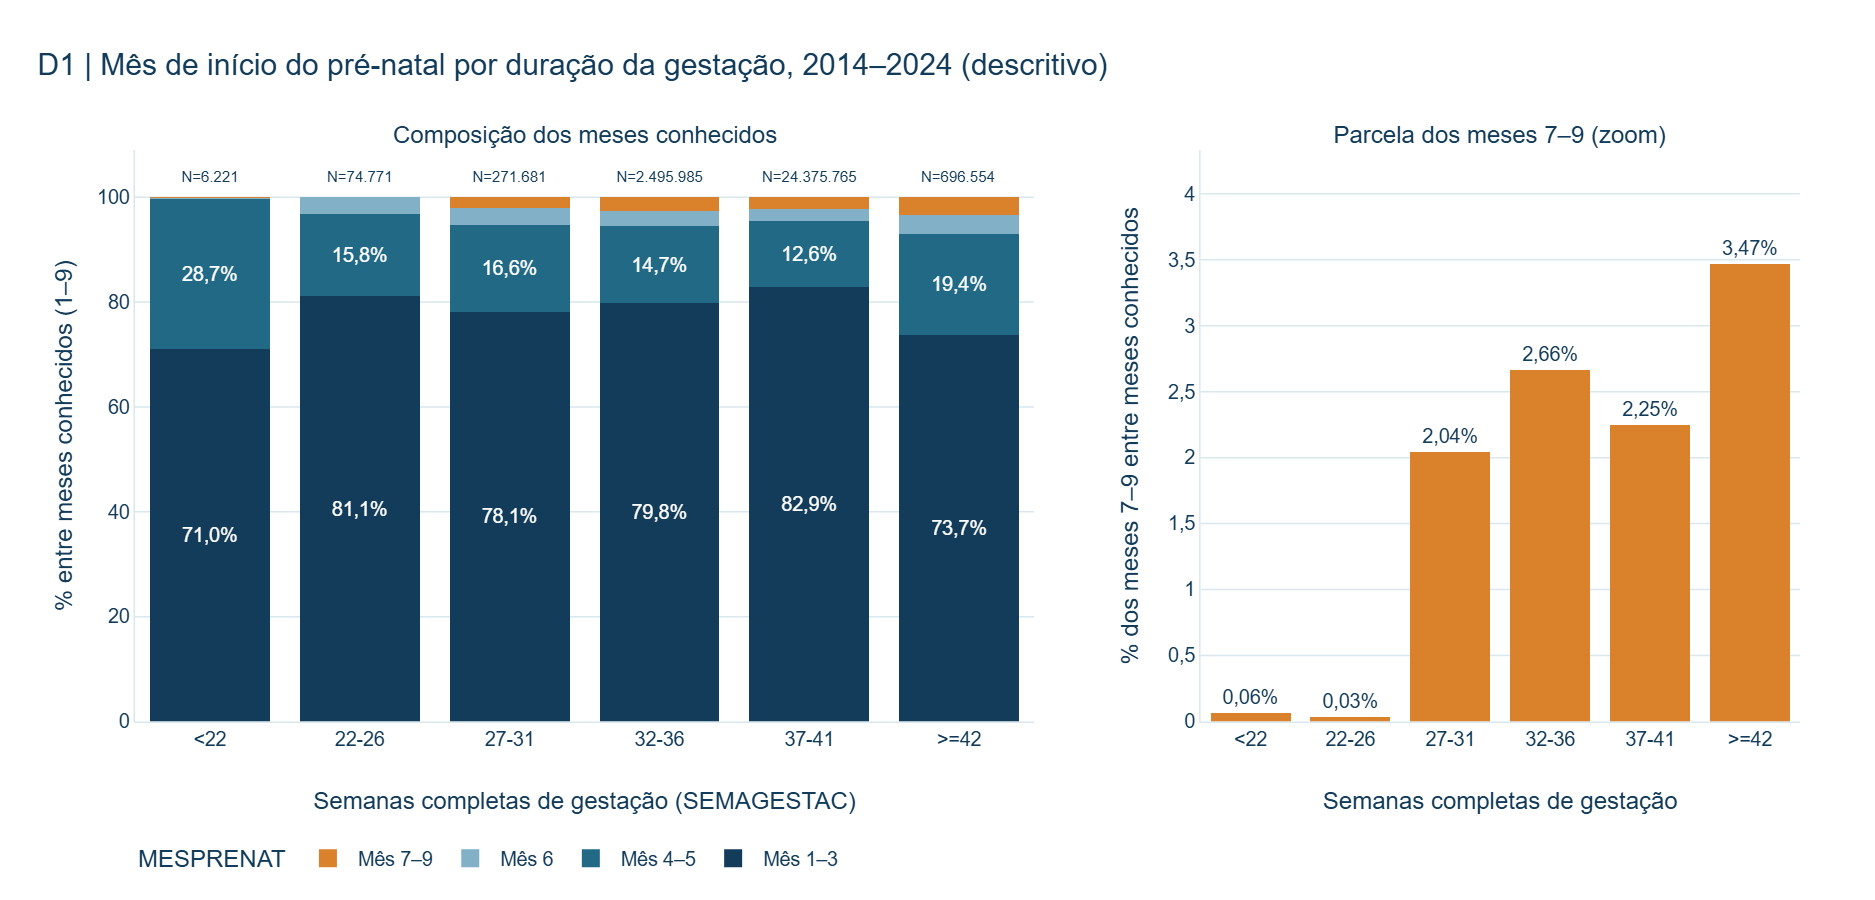

In [8]:
base_fig = conhecidos[conhecidos.faixa_ig != 'AUSENTE_OU_INVALIDA'].assign(grupo=lambda t: ap.grupo_d3(t.mes))
g = base_fig.groupby(['faixa_ig', 'grupo'], as_index=False).n.sum()
g['prop'] = g.n / g.groupby('faixa_ig').n.transform('sum')
faixas = [f for f in ap.FAIXAS_IG if f != 'AUSENTE_OU_INVALIDA']
def pct(v, casas=1):
    return f'{v:.{casas}f}%'.replace('.', ',')

fig = make_subplots(rows=1, cols=2, column_widths=[0.6, 0.4], horizontal_spacing=0.1,
                    subplot_titles=('Composição dos meses conhecidos', 'Parcela dos meses 7–9 (zoom)'))
for grupo in ('1-3', '4-5', '6', '7-9'):
    s = g[g.grupo == grupo].set_index('faixa_ig').reindex(faixas)
    fig.add_bar(x=faixas, y=100 * s.prop, name=ROTULO_GRUPO[grupo], marker_color=COR_GRUPO[grupo],
                text=[pct(v) if v >= 8 else '' for v in 100 * s.prop.fillna(0)], textposition='inside',
                insidetextanchor='middle', row=1, col=1)
n_faixa = g.groupby('faixa_ig').n.sum().reindex(faixas)
for f, n in n_faixa.items():
    fig.add_annotation(x=f, y=104, xref='x', yref='y', text=f'N={n:,.0f}'.replace(',', '.'), showarrow=False,
                       font=dict(size=10))
tardio = g[g.grupo == '7-9'].set_index('faixa_ig').reindex(faixas).prop.fillna(0)
fig.add_bar(x=faixas, y=100 * tardio, marker_color=COR_GRUPO['7-9'], showlegend=False, text=[pct(v, 2) for v in 100 * tardio],
            textposition='outside', row=1, col=2)
fig.update_layout(barmode='stack', legend_title_text='MESPRENAT', uniformtext=dict(minsize=10, mode='hide'))
fig.update_yaxes(title_text='% entre meses conhecidos (1–9)', range=[0, 109], row=1, col=1)
fig.update_yaxes(title_text='% dos meses 7–9 entre meses conhecidos', range=[0, 1.25 * 100 * tardio.max()], row=1, col=2)
fig.update_xaxes(title_text='Semanas completas de gestação (SEMAGESTAC)', type='category', row=1, col=1)
fig.update_xaxes(title_text='Semanas completas de gestação', type='category', row=1, col=2)
mostrar(fig, 'D1 | Mês de início do pré-natal por duração da gestação, 2014–2024 (descritivo)', 'fig1_d1_mesprenat_por_faixa_ig',
        altura=600, largura=1250)

**Leitura D1 (descritiva).**

- **Truncamento visível nas gestações mais curtas.** Entre meses conhecidos, 7–9 somam ≈0,06% abaixo de 22 semanas e ≈0,03% em 22–26 semanas, contra 2,0% em 27–31, 2,7% em 32–36, 2,3% em 37–41 e 3,5% em ≥42 (2014–2024). O mês 6 também quase some abaixo de 22 semanas (0,19%).
- **A checagem P1, como pré-registrada, falhou nos 11 anos.** Ela exigia proporção de 7–9 não decrescente de `<22` até `37–41`. Falha porque 32–36 tem **mais** meses 7–9 do que 37–41 (por exemplo, 2,66% contra 2,25% em 2014–2024) e porque a faixa `<22`, muito pequena, oscila. O padrão é, portanto, de truncamento claro abaixo de ~27 semanas, mas não monotônico acima disso. A diferença entre 32–36 e 37–41 é compatível com perfil de risco distinto de quem inicia tarde, o que este diagnóstico não separa.
- **GESTACAO e SEMAGESTAC são coerentes.** A categoria oficial `2` (22–27) contém a semana 27, que nas faixas desta auditoria cai em 27–31; toda semana 27 está em `GESTACAO=2`, como no dicionário oficial. Fora isso, há apenas 5 registros discordantes em 29,26 milhões com ambas preenchidas.
- **A IG ausente acompanha o mês ausente.** Na faixa sem IG válida, 41,3% dos registros também não têm mês conhecido, contra 4,4% em 37–41.

Nada disso indica efeito. O padrão é compatível com o mecanismo descrito por Vachuska (2025, p. 3), sem demonstrar sua magnitude.

## 8. D2 — consistência temporal MESPRENAT × SEMAGESTAC

In [9]:
with cronometro('D2'):
    d2 = ap.d2_tabelas(cubos['semanas'])
    salvar(d2['matriz'], 'd2_consistencia_mesprenat_semagestac', 'Matriz semana x mês com status diagnóstico e regra',
           'ano x semana x mês', 'ano, semanas, mes')
    salvar(d2['resumo_mes'], 'd2_resumo_status_por_mes', 'N por status diagnóstico e mês', 'ano x mês x status',
           'ano, mes, status_diagnostico')
anual = d2['matriz'][d2['matriz'].ano != '2014-2024']
resumo_status = anual.pivot_table(index='ano', columns='status_diagnostico', values='n', aggfunc='sum', fill_value=0)
resumo_status['N avaliado'] = resumo_status.sum(axis=1)
display(resumo_status)
tot = d2['resumo_mes'][d2['resumo_mes'].ano == '2014-2024'].pivot_table(index='mes', columns='status_diagnostico', values='n', fill_value=0)
tot['% L1 ou pior'] = 100 * tot[[c for c in tot.columns if c in ap.STATUS_CONSISTENCIA[:2]]].sum(axis=1) / tot.sum(axis=1)
print('2014–2024 por mês:')
display(tot.round(4))
print('Cobertura de SEMAGESTAC válida entre ELEGIVEL com mês 01–09:')
display(d2['cobertura_semagestac'].pivot(index='ano', columns='valida', values='n'))

status_diagnostico,POTENCIALMENTE_INCOMPATIVEL_L1,POTENCIALMENTE_INCOMPATIVEL_MESMO_COM_TOLERANCIA,POTENCIALMENTE_INCOMPATIVEL_SOMENTE_L2,SEM_INCOMPATIBILIDADE_DETECTADA,N avaliado
ano,,,,,
2014,5,2,3,2645796,2645806
2015,2,2,6,2701875,2701885
2016,5,1,5,2593106,2593117
2017,0,0,1,2664854,2664855
2018,1,1,2,2708891,2708895
2019,1,1,0,2625143,2625145
2020,2,2,2,2516127,2516133
2021,2,0,3,2465003,2465008
2022,3,0,2,2383801,2383806


2014–2024 por mês:


status_diagnostico,POTENCIALMENTE_INCOMPATIVEL_L1,POTENCIALMENTE_INCOMPATIVEL_MESMO_COM_TOLERANCIA,POTENCIALMENTE_INCOMPATIVEL_SOMENTE_L2,SEM_INCOMPATIBILIDADE_DETECTADA,% L1 ou pior
mes,,,,,
01,0.0000,0.0000,0.0000,"6,334,622.0000",0.0000
02,0.0000,0.0000,0.0000,"11,098,604.0000",0.0000
03,0.0000,0.0000,0.0000,"5,546,668.0000",0.0000
04,0.0000,0.0000,0.0000,"2,363,634.0000",0.0000
05,0.0000,0.0000,0.0000,"1,273,090.0000",0.0000
06,3.0000,0.0000,5.0000,"660,806.0000",0.0005
07,7.0000,2.0000,6.0000,"353,393.0000",0.0025
08,7.0000,4.0000,5.0000,"189,805.0000",0.0058
09,9.0000,6.0000,12.0000,"100,289.0000",0.0150


Cobertura de SEMAGESTAC válida entre ELEGIVEL com mês 01–09:


valida,False,True
ano,,
2014,45313,2645806
2015,43961,2701885
2016,33477,2593117
2017,30821,2664855
2018,25578,2708895
2019,20238,2625145
2020,19178,2516133
2021,16259,2465008
2022,13820,2383806


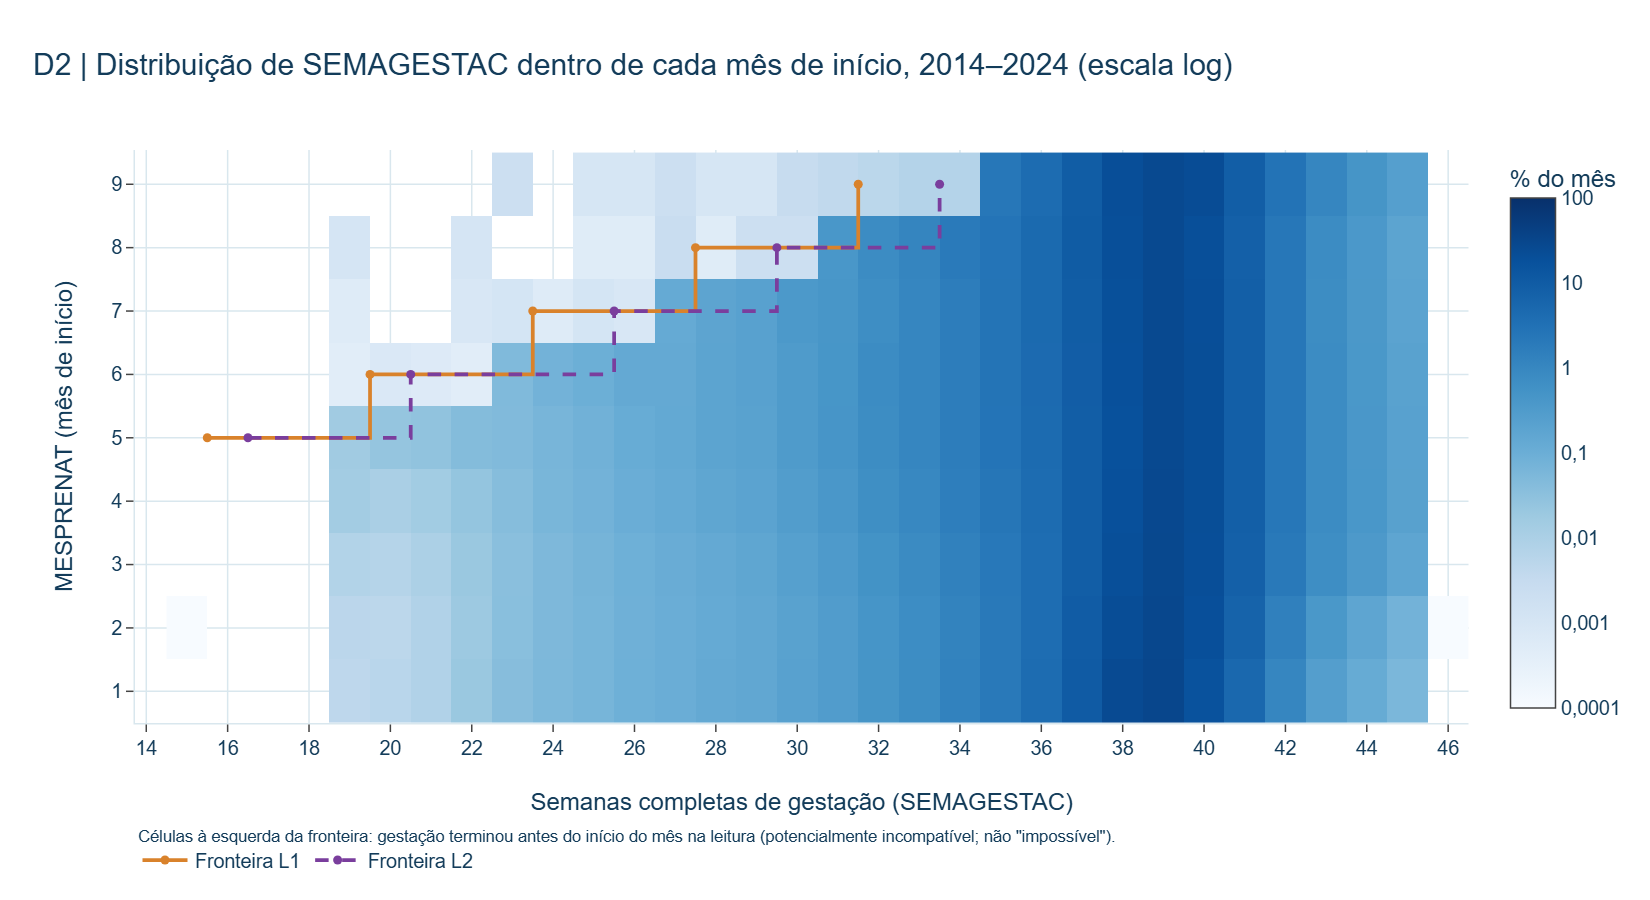

In [10]:
m = d2['matriz'][d2['matriz'].ano == '2014-2024']
semanas_eixo = list(range(int(m.semanas.min()), int(m.semanas.max()) + 1))
z = m.pivot_table(index='mes', columns='semanas', values='prop_no_mes').reindex(columns=semanas_eixo).reindex(list(ap.MESES_VALIDOS))
fig = go.Figure(go.Heatmap(x=semanas_eixo, y=[int(k) for k in z.index], z=np.log10(100 * z.to_numpy()),
                           colorscale='Blues', zmin=-4, zmax=2,
                           colorbar=dict(title='% do mês', tickvals=[-4, -3, -2, -1, 0, 1, 2],
                                         ticktext=['0,0001', '0,001', '0,01', '0,1', '1', '10', '100']),
                           hovertemplate='mês %{y}, %{x} semanas<extra></extra>'))
for leitura_, cor, traco in (('L1', '#D9822B', 'solid'), ('L2', '#7A3E9D', 'dash')):
    xs = [ap.limiar_semanas_afetadas(k, leitura_) + 0.5 for k in range(1, 10)]
    pontos = [(x, k) for x, k in zip(xs, range(1, 10)) if x >= semanas_eixo[0] - 0.5]
    fig.add_scatter(x=[p[0] for p in pontos], y=[p[1] for p in pontos], mode='lines+markers', name=f'Fronteira {leitura_}',
                    line=dict(color=cor, dash=traco, shape='hv', width=2.5), marker=dict(size=6))
fig.update_xaxes(title='Semanas completas de gestação (SEMAGESTAC)', dtick=2)
fig.update_yaxes(title='MESPRENAT (mês de início)', dtick=1)
fig.add_annotation(x=0.0, y=-0.22, xref='paper', yref='paper', showarrow=False, align='left', font=dict(size=11),
                   text='Células à esquerda da fronteira: gestação terminou antes do início do mês na leitura (potencialmente incompatível; não "impossível").')
mostrar(fig, 'D2 | Distribuição de SEMAGESTAC dentro de cada mês de início, 2014–2024 (escala log)', 'fig2_d2_heatmap_semagestac_mes', altura=600)

**Leitura D2.** A Figura 2 mostra a distribuição de `SEMAGESTAC` em cada mês de início acompanhando a fronteira mecânica (escada laranja/roxa): a massa do mês 7 começa por volta de 24–26 semanas, a do mês 8 por volta de 28–30 e a do mês 9 por volta de 32–34. Isso é exatamente o que o truncamento estrutural prevê.

Combinações potencialmente incompatíveis são raras:

- **38** registros em 27.920.977 avaliados em L1 (12 deles mesmo com tolerância de um mês) e outros 28 somente em L2;
- a maior fração em um mês-ano é 0,033% (mês 9, 2020);
- nenhuma combinação foi chamada de impossível e nenhum registro foi excluído.

Separadamente, o código `10` (2.607 registros, só em 2014) está fora do domínio oficial ("não existe início de pré-natal no 10º mês", Manual 2022, p. 79). As inconsistências existem, mas são numericamente imateriais. O problema temporal da V1 é **estrutural** (quem pode pertencer a cada mês), não de erro de registro.

## 9. D3 — CONSPRENAT=0 × MESPRENAT

In [11]:
with cronometro('D3'):
    d3 = ap.d3_tabelas(cubos['consprenat'])
    salvar(d3['longa'], 'd3_consprenat_mesprenat', 'CONSPRENAT x grupo MESPRENAT com três denominadores',
           'população x ano x UF/Brasil x CONSPRENAT x grupo', 'populacao, ano, uf, consprenat, grupo_mesprenat')
    salvar(d3['consprenat_zero'], 'd3_consprenat0_mesprenat', 'Recorte CONSPRENAT=0',
           'população x ano x UF/Brasil x grupo', 'populacao, ano, uf, grupo_mesprenat')
z0 = d3['consprenat_zero']
for pop in ('ELEGIVEL', 'BRUTA'):
    b = z0[(z0.populacao == pop) & (z0.uf == 'BRASIL')]
    t = b.pivot_table(index='ano', columns='grupo_mesprenat', values='prop_dentro_consprenat', fill_value=0) * 100
    t = t.reindex(columns=[c for c in ap.GRUPOS_D3 if c in t.columns])
    t['N CONSPRENAT=0'] = b.groupby('ano').n.sum()
    t['denominador total'] = b.groupby('ano').denominador_total.first()
    print(f'{pop}: distribuição (%) de MESPRENAT entre CONSPRENAT=0, Brasil')
    display(t.round(2))
br = d3['longa'][(d3['longa'].populacao == 'ELEGIVEL') & (d3['longa'].uf == 'BRASIL')]
quem = br[br.grupo_mesprenat.isin(['99', 'VAZIO'])].pivot_table(index='ano', columns=['grupo_mesprenat', 'consprenat'],
                                                                   values='prop_dentro_grupo_mesprenat', fill_value=0) * 100
print('ELEGIVEL: entre MESPRENAT 99 e vazio, % por categoria de CONSPRENAT')
display(quem.round(2))

ELEGIVEL: distribuição (%) de MESPRENAT entre CONSPRENAT=0, Brasil


grupo_mesprenat,1-3,4-5,6,7-9,99,VAZIO,OUTRO_INVALIDO,N CONSPRENAT=0,denominador total
ano,,,,,,,,,
2014,4.2800,0.7500,0.2400,0.9500,46.4300,47.3200,0.0200,16833,2908961
2015,3.9900,0.7000,0.2600,1.0300,45.5700,48.4600,0.0000,15633,2945992
2016,3.9800,0.6900,0.1500,1.0500,45.7800,48.3500,0.0000,15209,2790328
2017,3.7200,0.5800,0.1700,0.9800,46.3200,48.2400,0.0000,16418,2851529
2018,3.7100,0.6800,0.2000,0.8100,50.3500,44.2400,0.0000,17680,2871661
2019,4.1000,0.6500,0.2400,0.8000,47.0000,47.2100,0.0000,16210,2780821
2020,3.5900,0.5200,0.1500,0.9000,47.9000,46.9400,0.0000,16852,2664503
2021,3.7200,0.6000,0.2300,1.0300,47.9900,46.4400,0.0000,15850,2612784
2022,4.4300,0.5800,0.1000,1.3100,50.5200,43.0600,0.0000,15201,2498402


BRUTA: distribuição (%) de MESPRENAT entre CONSPRENAT=0, Brasil


grupo_mesprenat,1-3,4-5,6,7-9,99,VAZIO,OUTRO_INVALIDO,N CONSPRENAT=0,denominador total
ano,,,,,,,,,
2014,4.2700,0.7400,0.2400,0.9500,46.4100,47.3800,0.0200,17384,2979259
2015,3.9700,0.7100,0.2600,1.0100,45.5300,48.5200,0.0000,16133,3017668
2016,4.0000,0.7200,0.1500,1.0400,45.8100,48.2700,0.0000,15636,2857800
2017,3.7000,0.5900,0.1700,0.9500,46.3200,48.2700,0.0000,16897,2923535
2018,3.7300,0.6800,0.2100,0.8300,50.1700,44.3900,0.0000,18163,2944932
2019,4.1100,0.6400,0.2300,0.8200,46.8100,47.3800,0.0000,16636,2849146
2020,3.6400,0.5200,0.1500,0.8900,47.7200,47.0800,0.0000,17335,2730145
2021,3.7100,0.6300,0.2200,1.0100,47.9200,46.5200,0.0000,16300,2677101
2022,4.4200,0.5800,0.1000,1.2800,50.3500,43.2700,0.0000,15649,2561922


ELEGIVEL: entre MESPRENAT 99 e vazio, % por categoria de CONSPRENAT


grupo_mesprenat      99                                          VAZIO                                      
consprenat            0  01-03   04-06   07-98      99   VAZIO       0  01-03   04-06   07-98     99   VAZIO
ano                                                                                                         
2014             7.3800 9.3800 21.8600 34.1400 17.6500  9.5800  7.2900 7.7400 19.1800 29.5200 0.3900 35.8800
2015             8.0900 9.2100 19.5000 37.3200 15.6000 10.2700  6.7600 5.8200 14.5200 22.1900 0.0900 50.6300
2016             9.1700 9.3100 18.5600 35.7500 16.7100 10.5000  8.3800 6.1900 14.7800 25.2700 0.0900 45.2900
2017            10.5600 9.1200 18.9100 34.3400 15.4600 11.6200  9.4500 6.0000 13.9300 27.3100 0.1500 43.1600
2018            12.8600 9.2500 18.4300 35.5100 13.9000 10.0400 11.5000 5.6000 13.0200 27.1500 0.1600 42.5700
2019            11.7200 8.8800 17.8700 36.2900 14.8000 10.4400 10.8700 3.9700  9.8300 20.8400 0.1800 54.3200
2020            12.2400 8.7200 16.3200 32.7700 16.4900 13.4500 12.5100 4.9000  9.4100 17.3800 0.1800 55.6200
2021            12.1200 8.4800 15.8700 34.0300 15.4000 14.1100 10.7100 3.6300  7.4000 16.1500 0.1600 61.9500
2022            14.9500 8.3500 14.8800 34.1900 17.8600  9.7800 13.2500 4.4300  8.1600 20.9800 0.1600 53.0100
2023            18.6900 7.8600 14.9600 35.4400 13.2400  9.8100 13.7400 4.1800  8.9900 25.1500 0.1700 47.7700
2024            18.6400 7.1300 12.8600 36.5000 15.0800  9.7900 13.5200 3.0000  6.6700 22.6800 0.1100 54.0300

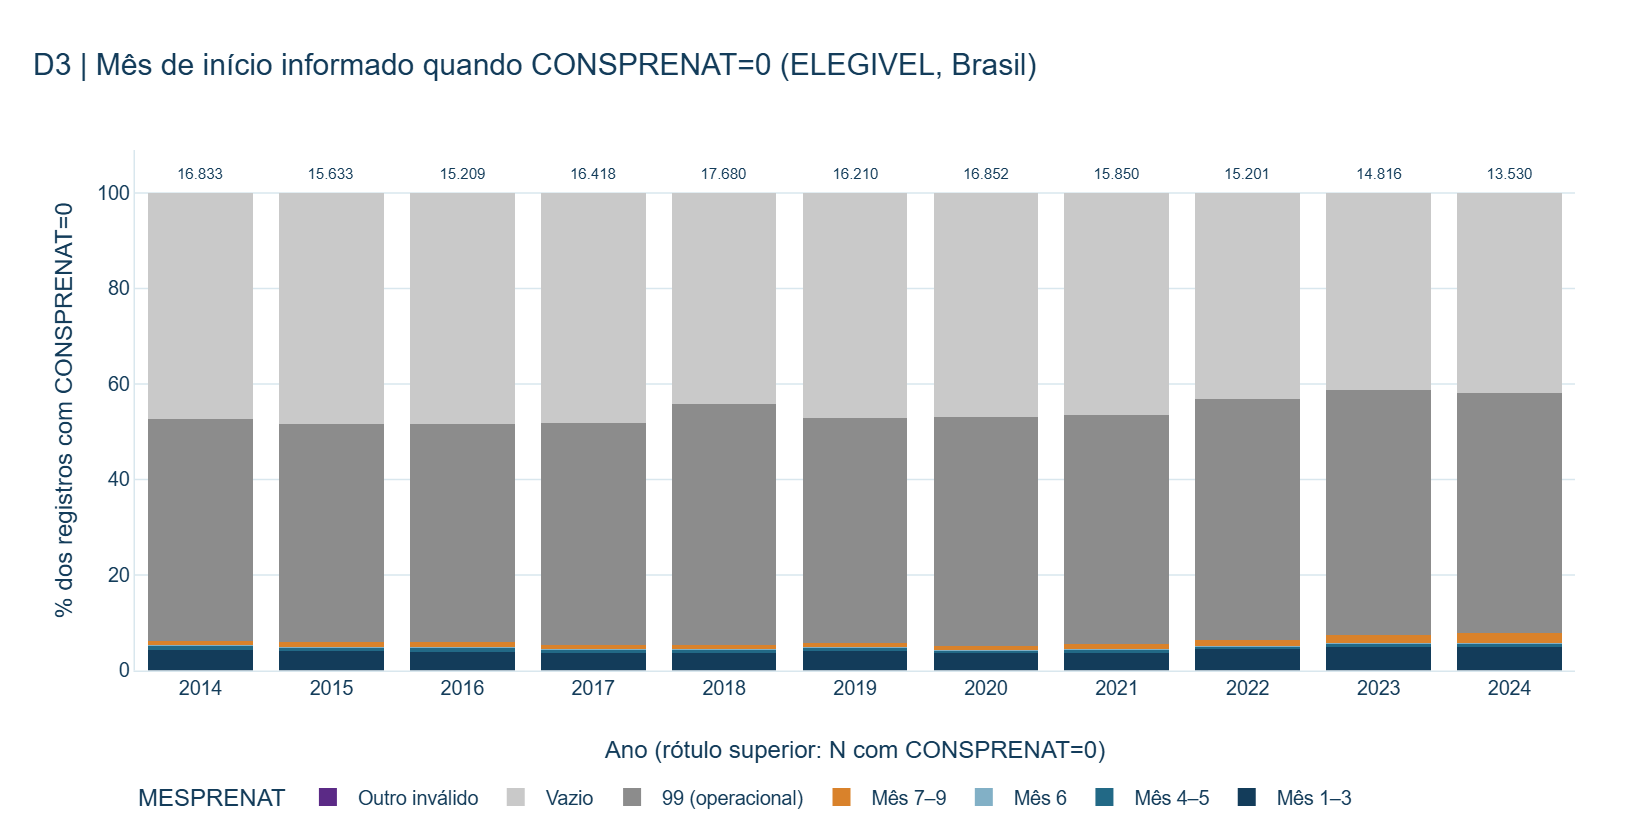

In [12]:
b = z0[(z0.populacao == 'ELEGIVEL') & (z0.uf == 'BRASIL')]
fig = go.Figure()
cores = {'1-3': CORES_IPT['AZUL_ESCURO'], '4-5': CORES_IPT['AZUL_MEDIO'], '6': CORES_IPT['AZUL_CLARO'], '7-9': '#D9822B',
         '99': '#8C8C8C', 'VAZIO': '#C9C9C9', 'OUTRO_INVALIDO': '#5B2A86'}
nomes = {'99': '99 (operacional)', 'VAZIO': 'Vazio', 'OUTRO_INVALIDO': 'Outro inválido', **ROTULO_GRUPO}
for grupo in ap.GRUPOS_D3:
    s = b[b.grupo_mesprenat == grupo].set_index('ano').reindex(ANOS)
    if s.n.fillna(0).sum() == 0:
        continue
    fig.add_bar(x=ANOS, y=100 * s.prop_dentro_consprenat.fillna(0), name=nomes[grupo], marker_color=cores[grupo])
for ano, n in b.groupby('ano').n.sum().items():
    fig.add_annotation(x=ano, y=104, text=f'{n:,.0f}'.replace(',', '.'), showarrow=False, font=dict(size=10))
fig.update_layout(barmode='stack', legend_title_text='MESPRENAT')
fig.update_yaxes(title='% dos registros com CONSPRENAT=0', range=[0, 109])
fig.update_xaxes(title='Ano (rótulo superior: N com CONSPRENAT=0)', dtick=1)
mostrar(fig, 'D3 | Mês de início informado quando CONSPRENAT=0 (ELEGIVEL, Brasil)', 'fig3_d3_consprenat0_mesprenat')

**Leitura D3.**

- **Volume.** `CONSPRENAT=0` é raro: 13,5–17,7 mil registros ELEGIVEL por ano (≈0,6%), em queda.
- **Mês informado com zero consultas** (ELEGIVEL, Brasil): `99` em 45,6%–51,4%, vazio em 41,2%–48,5%, meses 1–9 em 5,2%–7,9%. A contradição com mês válido está em alta desde 2020; a parcela de 7–9 passou de 0,8% para 2,1%.
- **Código dominante instável.** A categoria dominante alterna: vazio em 2014–2017 e 2019; `99` em 2018 e 2020–2024. Entre os 261 UF-anos com ≥ 100 registros `CONSPRENAT=0`, 113 têm categoria dominante diferente da nacional do mesmo ano. As UFs codificam a ausência de pré-natal no campo do mês de maneiras diferentes.
- **A recíproca também falha.** Entre `MESPRENAT=99`, só 7,4%–18,7% têm `CONSPRENAT=0`, e 33%–37% têm ≥ 7 consultas. Entre vazios, 6,8%–13,7% têm zero consultas e 36%–62% têm `CONSPRENAT` também vazio. `99` e vazio, portanto, **não** são "nenhum pré-natal": misturam início desconhecido de quem fez pré-natal, registros globalmente incompletos e uma minoria sem consultas.

O *landmark* exigiria tratar `CONSPRENAT=0` como "nunca iniciou". Isso tem semântica oficial, mas validade não demonstrada e codificação conjunta instável. Nenhum código foi convertido.

## 10. D4 — perfil dos MESPRENAT desconhecidos (DESCRITIVO / NÃO CAUSAL)

In [13]:
with cronometro('D4'):
    d4 = ap.d4_tabelas(cubos['perfil_categorico'], cubos['perfil_numerico'])
    salvar(d4['perfil'], 'd4_perfil_mesprenat_desconhecido', 'Perfil categórico por grupo de MESPRENAT (ELEGIVEL)',
           'ano x grupo x variável x nível', 'ano, grupo, variavel, nivel')
    salvar(d4['numerico'], 'd4_perfil_numerico', 'N, idade materna e prevalência de BPN por grupo',
           'ano x grupo', 'ano, grupo')
    salvar(d4['smd'], 'd4_smd_missingness', 'SMD grupo desconhecido vs conhecido - seleção/missingness, não balanceamento',
           'ano x grupo x variável x nível', 'ano, grupo, variavel, nivel')
num = d4['numerico']
display(num[num.ano == '2014-2024'][['grupo', 'n', 'prevalencia_bpn', 'idade_media', 'idade_dp']].assign(
    prevalencia_bpn=lambda t: 100 * t.prevalencia_bpn).rename(columns={'prevalencia_bpn': 'BPN (%)'}))
print('BPN (%) por ano e grupo:')
display((100 * num[num.ano != '2014-2024'].pivot(index='ano', columns='grupo', values='prevalencia_bpn')).round(2))
perf = d4['perfil'][(d4['perfil'].ano == '2014-2024') & d4['perfil'].variavel.isin(['FAIXA_IG', 'ESCOLARIDADE_MAE', 'PARIDADE_CAT', 'RACA_COR_MAE'])]
display((100 * perf.pivot_table(index=['variavel', 'nivel'], columns='grupo', values='prop')).round(2))
smd = d4['smd']
pior = smd[smd.ano == '2014-2024'].loc[lambda t: t.groupby(['grupo', 'variavel']).abs_smd.idxmax()]
print('Maior |SMD| por variável, 2014–2024 (seleção/missingness, não balanceamento):')
display(pior[['grupo', 'variavel', 'nivel', 'prop_grupo', 'prop_conhecido', 'smd']].sort_values(['grupo', 'variavel']))
anos_smd = smd[smd.ano != '2014-2024']
print('Comparações anuais com |SMD| >= 0,10, por grupo e tipo:')
display(anos_smd.assign(acima=anos_smd.abs_smd >= ap.SMD_REFERENCIA).pivot_table(index=['grupo', 'tipo'], values='acima', aggfunc=['sum', 'count']))

,grupo,n,BPN (%),idade_media,idade_dp
4,99,733543,12.4377,26.1266,6.8734
5,CONHECIDO,28194211,7.2779,26.9671,6.7272
6,OUTRO_INVALIDO,2576,2.8339,25.0113,6.3938
7,VAZIO,799182,10.6887,26.0257,6.8058


BPN (%) por ano e grupo:


grupo,99,CONHECIDO,OUTRO_INVALIDO,VAZIO
ano,,,,
2014,11.2900,6.9300,2.8300,9.9900
2015,11.8200,6.9800,NaN,9.7800
2016,12.1100,7.0400,NaN,10.1100
2017,12.0700,7.0300,NaN,10.6500
2018,12.2200,7.0200,NaN,10.6900
2019,12.1700,7.1900,NaN,10.2300
2020,12.1000,7.0900,NaN,10.7000
2021,12.4400,7.3700,NaN,11.4100
2022,14.0600,7.8500,NaN,12.5700


grupo                                     99  CONHECIDO  OUTRO_INVALIDO   VAZIO
variavel         nivel                                                         
ESCOLARIDADE_MAE 0                    1.4700     0.3600          1.6700  1.3100
                 1                    6.5600     3.6200         10.2100  6.0800
                 2                   29.7500    21.9600         33.1100 22.7200
                 3                   45.6900    51.8900         39.8700 30.9900
                 4                    3.5000     5.0900          3.8400  2.8500
                 5                    8.1300    16.1300          6.7200  7.4100
                 IGNORADO             4.9000     0.9600          4.5800 28.6300
FAIXA_IG         22-26                0.8200     0.2700             NaN  0.6600
                 27-31                2.0100     0.9600          0.0400  1.7100
                 32-36               10.1800     8.8500          0.0800  8.9700
                 37-41               75.8000    86.4600         72.5900 71.0100
                 <22                  0.1000     0.0200             NaN  0.1000
                 >=42                 1.8100     2.4700         14.4400  2.1000
                 AUSENTE_OU_INVALIDA  9.2800     0.9700         12.8500 15.4600
PARIDADE_CAT     0                   33.2700    38.7200         37.3100 35.3900
                 1                   66.7300    61.2800         62.6900 64.6100
RACA_COR_MAE     1                   22.3300    34.8500         22.8600 12.1300
                 2                    7.3100     6.2100          5.7500  3.8700
                 3                    0.3400     0.4300          0.6600  0.2100
                 4                   62.8100    54.9700         64.9500 47.9800
                 5                    1.6800     0.9000          1.2400  1.4400
                 IGNORADO             5.5400     2.6500          4.5400 34.3700

Maior |SMD| por variável, 2014–2024 (seleção/missingness, não balanceamento):


,grupo,variavel,nivel,prop_grupo,prop_conhecido,smd
170,99,ESCOLARIDADE_MAE,5,0.0813,0.1613,-0.2468
219,99,IDADEMAE_NUM,media,26.1266,26.9671,-0.1236
172,99,IDADE_AUSENTE,1,0.0001,0.0000,0.0112
173,99,PARIDADE_CAT,0,0.3327,0.3872,-0.1138
178,99,PERDAS_FETAIS_CAT,IGNORADO,0.0634,0.0461,0.0761
179,99,RACA_COR_MAE,1,0.2233,0.3485,-0.2797
186,99,SITUACAO_CONJUGAL,2,0.2129,0.3258,-0.2565
209,99,UF_RESIDENCIA,33,0.1599,0.0727,0.2744
218,99,Y_BAIXO_PESO,1,0.1244,0.0728,0.1737
280,OUTRO_INVALIDO,ESCOLARIDADE_MAE,5,0.0672,0.1613,-0.2991


Comparações anuais com |SMD| >= 0,10, por grupo e tipo:


sum count
                    acima acima
grupo          tipo            
99             X      247   594
               Y       11    11
OUTRO_INVALIDO X       22    54
               Y        1     1
VAZIO          X      323   594
               Y       11    11

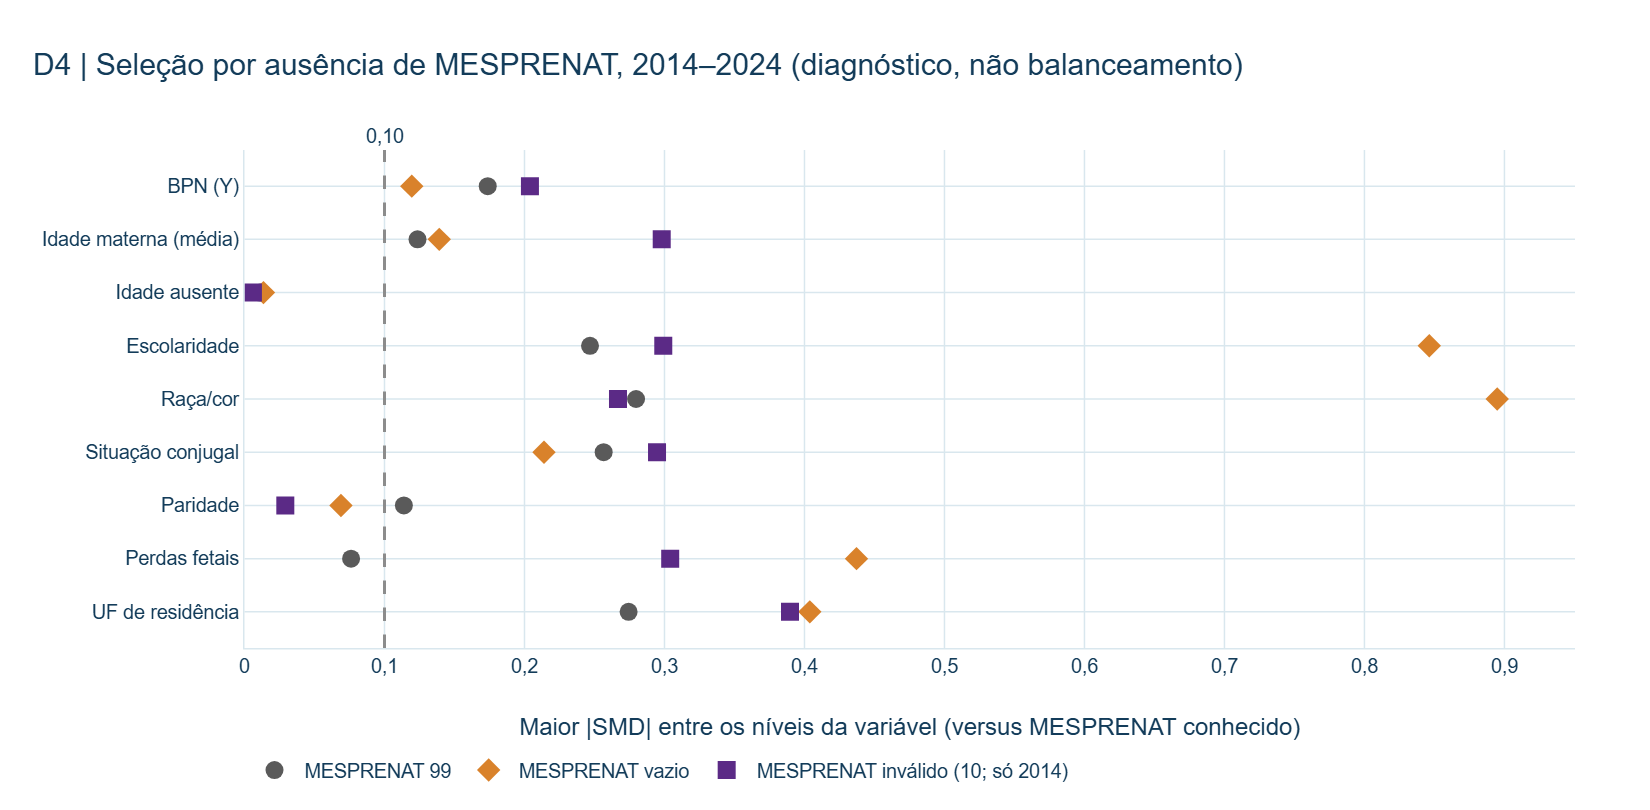

In [14]:
p = pior.copy()
ordem_var = ['Y_BAIXO_PESO', 'IDADEMAE_NUM', 'IDADE_AUSENTE', 'ESCOLARIDADE_MAE', 'RACA_COR_MAE', 'SITUACAO_CONJUGAL',
             'PARIDADE_CAT', 'PERDAS_FETAIS_CAT', 'UF_RESIDENCIA']
rotulos_var = {'Y_BAIXO_PESO': 'BPN (Y)', 'IDADEMAE_NUM': 'Idade materna (média)', 'IDADE_AUSENTE': 'Idade ausente',
               'ESCOLARIDADE_MAE': 'Escolaridade', 'RACA_COR_MAE': 'Raça/cor', 'SITUACAO_CONJUGAL': 'Situação conjugal',
               'PARIDADE_CAT': 'Paridade', 'PERDAS_FETAIS_CAT': 'Perdas fetais', 'UF_RESIDENCIA': 'UF de residência'}
fig = go.Figure()
nomes_grupo = {'99': 'MESPRENAT 99', 'VAZIO': 'MESPRENAT vazio', 'OUTRO_INVALIDO': 'MESPRENAT inválido (10; só 2014)'}
for grupo, cor, simbolo in (('99', '#5A5A5A', 'circle'), ('VAZIO', '#D9822B', 'diamond'), ('OUTRO_INVALIDO', '#5B2A86', 'square')):
    s = p[p.grupo == grupo].set_index('variavel').reindex(ordem_var).dropna(subset=['smd'])
    if s.empty:
        continue
    fig.add_scatter(x=s.smd.abs(), y=[rotulos_var[v] for v in s.index], mode='markers', name=nomes_grupo[grupo],
                    marker=dict(size=12, color=cor, symbol=simbolo),
                    text=[f'nível {n}' for n in s.nivel], hovertemplate='%{y}: |SMD|=%{x:.3f} (%{text})<extra></extra>')
fig.add_vline(x=ap.SMD_REFERENCIA, line_dash='dash', line_color='#8C8C8C', annotation_text='0,10', annotation_position='top')
fig.update_xaxes(title='Maior |SMD| entre os níveis da variável (versus MESPRENAT conhecido)', rangemode='tozero')
fig.update_yaxes(title='', autorange='reversed')
mostrar(fig, 'D4 | Seleção por ausência de MESPRENAT, 2014–2024 (diagnóstico, não balanceamento)', 'fig4_d4_smd_missingness', altura=540)

**Leitura D4 (DESCRITIVO / NÃO CAUSAL).**

- **Y difere entre grupos.** O BPN é 12,4% em `99`, 10,7% em vazio e 7,3% no mês conhecido. A diferença cresce ao longo do tempo à medida que o desconhecido diminui; em 2024, o BPN em `99` chega a 15,1%.
- **IG.** Os grupos desconhecidos têm mais prematuros (27–31 semanas: 2,0% em `99` contra 0,96%) e muito mais IG ausente (9,3% e 15,5% contra 1,0%).
- **Vazio indica registro incompleto como um todo.** Escolaridade ignorada aparece em 28,6% dos vazios (contra 1,0%), e raça/cor ignorada em 34,4% (contra 2,7%).
- **Composição regional diferente.** O RJ responde por 16,0% dos `99`, contra 7,3% dos conhecidos; SP, por 7,2% dos vazios, contra 20,9%.
- **Diferencial em Y e em X em todos os anos.** 615 de 1.265 comparações anuais (grupo × variável × nível) atingem |SMD| ≥ 0,10, inclusive BPN.

O SMD aqui é diagnóstico de seleção/ausência de dados, não balanceamento causal. A V1, ao exigir mês conhecido, seleciona uma população com BPN bruto menor. Este diagnóstico não diz em que direção isso afeta o contraste T×Y.

## 11. D5 — ausência de MESPRENAT por ano × UF

In [15]:
with cronometro('D5'):
    d5 = ap.d5_tabelas(cubos['ig_uf'])
    salvar(d5, 'd5_missing_mesprenat_ano_uf', 'N, denominador e proporções de 99, vazio e outros inválidos',
           'população x ano x UF/Brasil', 'populacao, ano, uf')
br5 = d5[d5.uf == 'BRASIL'].set_index(['populacao', 'ano'])
display((100 * br5[['prop_99', 'prop_VAZIO', 'prop_OUTRO_INVALIDO', 'prop_desconhecido_total']]).round(3)
        .join(br5[['n_99', 'n_VAZIO', 'n_OUTRO_INVALIDO', 'denominador']]))
uf5 = d5[(d5.populacao == 'BRUTA') & (d5.uf != 'BRASIL')]
amp = uf5.groupby('ano').prop_desconhecido_total.agg(['min', 'median', 'max']) * 100
print('BRUTA: dispersão entre UFs da % de desconhecido (mín/mediana/máx):')
display(amp.round(2))
disc = uf5[uf5.triagem_discrepante].assign(UF=lambda t: t.uf.map(UF_SIGLA))
print(f'UF-anos na triagem descritiva (>= {ap.FATOR_DISCREPANCIA_UF:g}x a nacional, N >= {ap.CELULA_MINIMA}):', len(disc))
display(disc[['ano', 'UF', 'denominador', 'n_99', 'n_VAZIO', 'prop_desconhecido_total', 'razao_vs_brasil']].sort_values(['UF', 'ano']))

prop_99  prop_VAZIO  prop_OUTRO_INVALIDO  prop_desconhecido_total    n_99  n_VAZIO  n_OUTRO_INVALIDO  denominador
populacao ano                                                                                                                    
BRUTA     2014   3.6480      3.8320               0.0880                   7.5670  108669   114169              2607      2979259
          2015   2.9990      3.8610               0.0000                   6.8600   90495   116524                 0      3017668
          2016   2.7310      3.2170               0.0000                   5.9480   78053    91924                 0      2857800
          2017   2.5320      3.0860               0.0000                   5.6190   74034    90228                 0      2923535
          2018   2.4140      2.5000               0.0000                   4.9140   71076    73628                 0      2944932
          2019   2.3410      2.5550               0.0000                   4.8960   66700    72788                 0      2849146
          2020   2.4790      2.4220               0.0000                   4.9010   67685    66129                 0      2730145
          2021   2.4050      2.6630               0.0000                   5.0670   64374    71287                 0      2677101
          2022   2.0600      2.0040               0.0000                   4.0640   52767    51344                 0      2561922
          2023   1.6520      1.8130               0.0000                   3.4660   41931    46016                 0      2537576
          2024   1.5720      1.8150               0.0000                   3.3870   37569    43368                 0      2389325
ELEGIVEL  2014   3.6410      3.7590               0.0890                   7.4890  105928   109338              2576      2908961
          2015   2.9880      3.8060               0.0000                   6.7940   88024   112122                 0      2945992
          2016   2.7220      3.1460               0.0000                   5.8680   75951    87783                 0      2790328
          2017   2.5260      2.9390               0.0000                   5.4660   72039    83814                 0      2851529
          2018   2.4100      2.3680               0.0000                   4.7770   69197    67991                 0      2871661
          2019   2.3380      2.5320               0.0000                   4.8700   65024    70414                 0      2780821
          2020   2.4750      2.3730               0.0000                   4.8490   65956    63236                 0      2664503
          2021   2.4030      2.6310               0.0000                   5.0340   62776    68741                 0      2612784
          2022   2.0570      1.9770               0.0000                   4.0340   51380    49396                 0      2498402
          2023   1.6470      1.7970               0.0000                   3.4440   40757    44462                 0      2474565
          2024   1.5670      1.7980               0.0000                   3.3650   36511    41885                 0      2329966

BRUTA: dispersão entre UFs da % de desconhecido (mín/mediana/máx):


,min,median,max
ano,,,
2014,3.4200,7.6700,24.4400
2015,2.3700,6.6300,20.4800
2016,2.0600,6.5000,22.9000
2017,1.5600,5.8400,25.7700
2018,1.4700,4.5400,23.0200
2019,1.3600,4.7800,15.9900
2020,1.2400,4.7900,14.9600
2021,1.1700,5.0000,23.3700
2022,1.2200,3.9000,16.6100


UF-anos na triagem descritiva (>= 2x a nacional, N >= 100): 43


,ano,UF,denominador,n_99,n_VAZIO,prop_desconhecido_total,razao_vs_brasil
1,2014,AC,17139,327,3492,0.2297,3.0356
29,2015,AC,16980,554,2923,0.2048,2.9849
57,2016,AC,15773,208,2839,0.1932,3.2479
85,2017,AC,16358,161,4055,0.2577,4.5871
113,2018,AC,16543,147,3662,0.2302,4.6859
141,2019,AC,16280,136,1752,0.1160,2.3688
197,2021,AC,15699,499,3170,0.2337,4.6120
225,2022,AC,14483,582,1824,0.1661,4.0880
253,2023,AC,14473,510,558,0.0738,2.1292
281,2024,AC,13101,493,466,0.0732,2.1609


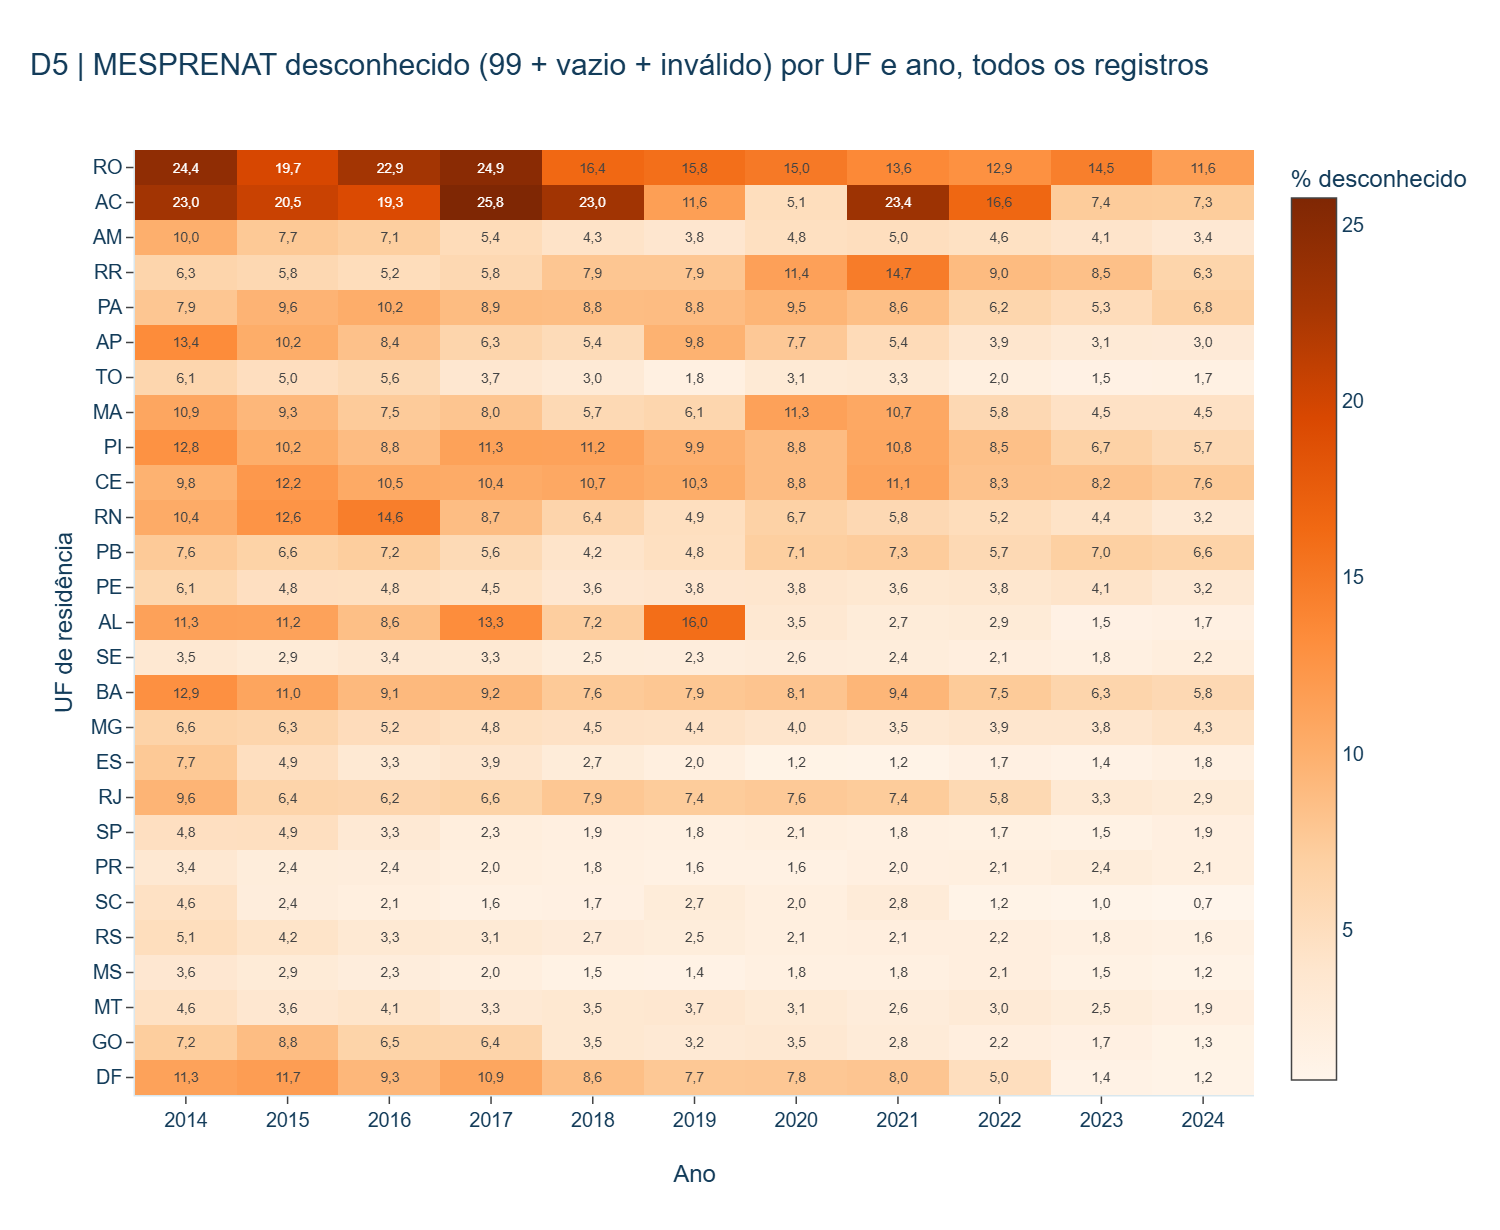

In [16]:
h = uf5.assign(UF=uf5.uf.map(UF_SIGLA))
ordem_uf = [UF_SIGLA[k] for k in sorted(k for k in UF_SIGLA if k != 'IGNORADO')] + (['IGN'] if 'IGN' in set(h.UF) else [])
z = h.pivot_table(index='UF', columns='ano', values='prop_desconhecido_total').reindex(ordem_uf) * 100
fig = go.Figure(go.Heatmap(z=z.to_numpy(), x=[str(a) for a in z.columns], y=z.index, colorscale='Oranges',
                           text=np.vectorize(lambda v: '' if np.isnan(v) else f'{v:.1f}'.replace('.', ','))(z.to_numpy()),
                           texttemplate='%{text}', textfont=dict(size=9), colorbar=dict(title='% desconhecido')))
fig.update_xaxes(title='Ano', type='category')
fig.update_yaxes(title='UF de residência', autorange='reversed')
mostrar(fig, 'D5 | MESPRENAT desconhecido (99 + vazio + inválido) por UF e ano, todos os registros', 'fig5_d5_missing_uf_ano', altura=820, largura=1000)

**Leitura D5.**

- **Tendência.** O desconhecido caiu de 7,57% (2014) para 3,39% (2024) em todos os registros: `99` de 3,65% para 1,57%, vazio de 3,83% para 1,82%. Outros inválidos (código `10`) aparecem só em 2014 (0,09%).
- **Heterogeneidade regional.** Em 2024, a parcela vai de 0,75% (SC) a 11,6% (RO); em 2014, de 3,4% a 24,4%.
- **UF-anos na triagem descritiva (≥ 2× a nacional): 43.** RO em todos os 11 anos; AC em 10 (todos, exceto 2020); CE em 6 (2018, 2019, 2021–2024); PI em 5; RR em 4 (2020–2023); AL e MA em 2; RN, PA e PB em 1.
- **Saltos isolados.** Há quedas e altas abruptas, como AC 2020 (5,1%) entre anos acima de 20%, e AL 2019 (16,0%) seguido de 3,5%. São compatíveis com mudanças locais de processo, não verificadas aqui.

Nenhuma UF foi removida. A triagem é convenção de leitura, não critério.

## 12. D6 — heaping e distribuição 1–9

In [17]:
with cronometro('D6'):
    d6 = ap.d6_tabelas(cubos['ig_uf'], cubos['processo'])
    salvar(d6['distribuicao'], 'd6_heaping_mesprenat', 'Distribuição de MESPRENAT 1-9', 'população x ano x UF/Brasil x mês',
           'populacao, ano, uf, mes')
    salvar(d6['indicadores'], 'd6_indicadores_heaping', 'Indicadores locais pré-especificados', 'população x ano x UF/Brasil',
           'populacao, ano, uf')
    salvar(d6['indicadores_dum'], 'd6_indicadores_por_dum', 'Indicadores por presença de DTULTMENST', 'população x ano x DUM',
           'populacao, ano, dum')
    salvar(d6['indicadores_tpmetestim'], 'd6_indicadores_por_tpmetestim', 'Indicadores por TPMETESTIM',
           'população x ano x TPMETESTIM', 'populacao, ano, tpmetestim')
    salvar(d6['dum_tpmetestim'], 'd6_dum_tpmetestim_semagestac', 'Processo de mensuração da IG: DUM x TPMETESTIM x SEMAGESTAC',
           'população x ano x DUM x TPMETESTIM x status', 'populacao, ano, dum, tpmetestim, semanas_status')
dist = d6['distribuicao'][(d6['distribuicao'].populacao == 'BRUTA') & (d6['distribuicao'].uf == 'BRASIL')]
display((100 * dist.pivot(index='ano', columns='mes', values='prop_meses_1_9')).round(2))
ind = d6['indicadores']
display(ind[(ind.uf == 'BRASIL')].set_index(['populacao', 'ano']).drop(columns='uf').round(3))
ind_uf = ind[(ind.populacao == 'BRUTA') & (ind.uf != 'BRASIL') & (ind.uf != 'IGNORADO')]
print('Dispersão entre UFs (BRUTA): razão 3/4 e vizinhança do 3')
display(ind_uf.groupby('ano')[['razao_3_4', 'vizinhanca_3']].agg(['min', 'median', 'max']).round(2))
for nome, chave in (('indicadores_dum', 'dum'), ('indicadores_tpmetestim', 'tpmetestim')):
    t = d6[nome][d6[nome].populacao == 'BRUTA']
    print(f'Por {chave} (BRUTA): razão 3/4')
    display(t.pivot(index='ano', columns=chave, values='razao_3_4').round(2))
cr = d6['dum_tpmetestim'][d6['dum_tpmetestim'].populacao == 'BRUTA']
print('DUM x TPMETESTIM x SEMAGESTAC, 2014–2024 (BRUTA, N):')
display(cr.pivot_table(index=['dum', 'tpmetestim'], columns='semanas_status', values='n', aggfunc='sum', fill_value=0))

mes,01,02,03,04,05,06,07,08,09
ano,,,,,,,,,
2014,21.5000,35.2000,21.9200,10.2500,5.4800,2.8500,1.5400,0.8100,0.4300
2015,21.3900,36.2600,21.8300,9.9800,5.2600,2.6600,1.4300,0.7300,0.4700
2016,22.0700,36.8800,21.3800,9.5900,5.0200,2.5800,1.3600,0.7100,0.4200
2017,22.8900,37.5300,20.6600,9.1200,4.9000,2.5000,1.3200,0.7000,0.3800
2018,22.7800,38.6900,20.3300,8.8500,4.6900,2.4100,1.2700,0.6500,0.3300
2019,22.9000,39.8300,19.7300,8.5000,4.5100,2.3200,1.2200,0.6400,0.3300
2020,22.7300,40.5500,19.2700,8.2500,4.5300,2.3600,1.2700,0.6800,0.3700
2021,23.2700,42.2100,18.4900,7.5100,4.1300,2.1800,1.2100,0.6600,0.3500
2022,23.2300,42.6400,18.3800,7.3000,4.0600,2.1900,1.1900,0.6700,0.3500


n_meses_1_9  razao_3_4  razao_2_3  vizinhanca_3  vizinhanca_2  salto_3_4_pp
populacao ano                                                                                
BRUTA     2014 2,753,814.0000     2.1380     1.6060        0.9650        1.6210       11.6690
          2015 2,810,649.0000     2.1860     1.6610        0.9440        1.6780       11.8430
          2016 2,687,823.0000     2.2300     1.7260        0.9200        1.6980       11.7900
          2017 2,759,273.0000     2.2660     1.8160        0.8860        1.7230       11.5450
          2018 2,800,228.0000     2.2980     1.9030        0.8550        1.7950       11.4860
          2019 2,709,658.0000     2.3210     2.0180        0.8170        1.8680       11.2320
          2020 2,596,331.0000     2.3370     2.1050        0.7900        1.9310       11.0210
          2021 2,541,440.0000     2.4640     2.2830        0.7440        2.0220       10.9870
          2022 2,457,811.0000     2.5190     2.3190        0.7360        2.0490       11.0840
          2023 2,449,629.0000     2.6440     2.4320        0.7120        2.1070       11.1860
          2024 2,308,388.0000     2.7260     2.5690        0.6810        2.1450       11.0080
ELEGIVEL  2014 2,691,119.0000     2.1370     1.6040        0.9650        1.6260       11.6830
          2015 2,745,846.0000     2.1860     1.6580        0.9460        1.6820       11.8730
          2016 2,626,594.0000     2.2320     1.7220        0.9220        1.7020       11.8280
          2017 2,695,676.0000     2.2650     1.8130        0.8870        1.7260       11.5640
          2018 2,734,473.0000     2.2990     1.8980        0.8570        1.7980       11.5180
          2019 2,645,383.0000     2.3220     2.0130        0.8180        1.8710       11.2630
          2020 2,535,311.0000     2.3360     2.1000        0.7910        1.9340       11.0460
          2021 2,481,267.0000     2.4650     2.2760        0.7460        2.0230       11.0160
          2022 2,397,626.0000     2.5180     2.3130        0.7380        2.0500       11.1060
          2023 2,389,346.0000     2.6460     2.4250        0.7140        2.1080       11.2200
          2024 2,251,570.0000     2.7250     2.5640        0.6820        2.1470       11.0260

Dispersão entre UFs (BRUTA): razão 3/4 e vizinhança do 3


razao_3_4               vizinhanca_3              
           min median    max          min median    max
ano                                                    
2014    1.4100 2.0600 2.9400       0.8200 1.0300 1.3900
2015    1.3900 2.1800 2.9700       0.7400 0.9900 1.3400
2016    1.5300 2.1600 3.1400       0.7600 0.9300 1.3300
2017    1.5300 2.1800 2.8700       0.7100 0.9100 1.3500
2018    1.5100 2.2600 2.8200       0.6800 0.8600 1.3100
2019    1.4600 2.3100 2.7900       0.6800 0.8300 1.2100
2020    1.6400 2.3000 2.8900       0.6500 0.7900 1.1800
2021    1.6500 2.4000 2.9200       0.6100 0.7600 1.1100
2022    1.7500 2.4800 3.0300       0.6000 0.7500 1.1600
2023    1.8800 2.5300 3.3700       0.5900 0.7200 1.0700
2024    1.8800 2.7200 3.7900       0.5500 0.6900 1.1500

Por dum (BRUTA): razão 3/4


dum,AUSENTE,PRESENTE_VALIDA
ano,,
2014,2.0500,2.2000
2015,2.1200,2.2400
2016,2.1900,2.2600
2017,2.2100,2.3100
2018,2.2000,2.3800
2019,2.2100,2.4200
2020,2.2600,2.4100
2021,2.4000,2.5300
2022,2.4400,2.6000


Por tpmetestim (BRUTA): razão 3/4


tpmetestim,1,2,8,9,VAZIO
ano,,,,,
2014,2.0100,2.1000,2.2000,2.1700,1.9700
2015,2.1000,2.1700,2.2400,2.1100,1.8800
2016,2.1800,2.2900,2.2600,2.1000,1.7600
2017,2.1400,2.3300,2.3100,2.1800,1.9200
2018,2.1500,2.2700,2.3800,2.2500,1.8700
2019,2.1500,2.2800,2.4200,2.2800,1.7900
2020,2.2100,2.3000,2.4100,2.3400,1.9600
2021,2.3400,2.4700,2.5300,2.4000,1.9600
2022,2.3700,2.5100,2.6000,2.4200,2.1200


DUM x TPMETESTIM x SEMAGESTAC, 2014–2024 (BRUTA, N):


semanas_status                VALIDA   VAZIO
dum             tpmetestim                  
AUSENTE         1            5672292       0
                2            6086006       0
                9            2389444       0
                VAZIO         179853  483706
PRESENTE_VALIDA 8           15656968      14
                VAZIO              7     119

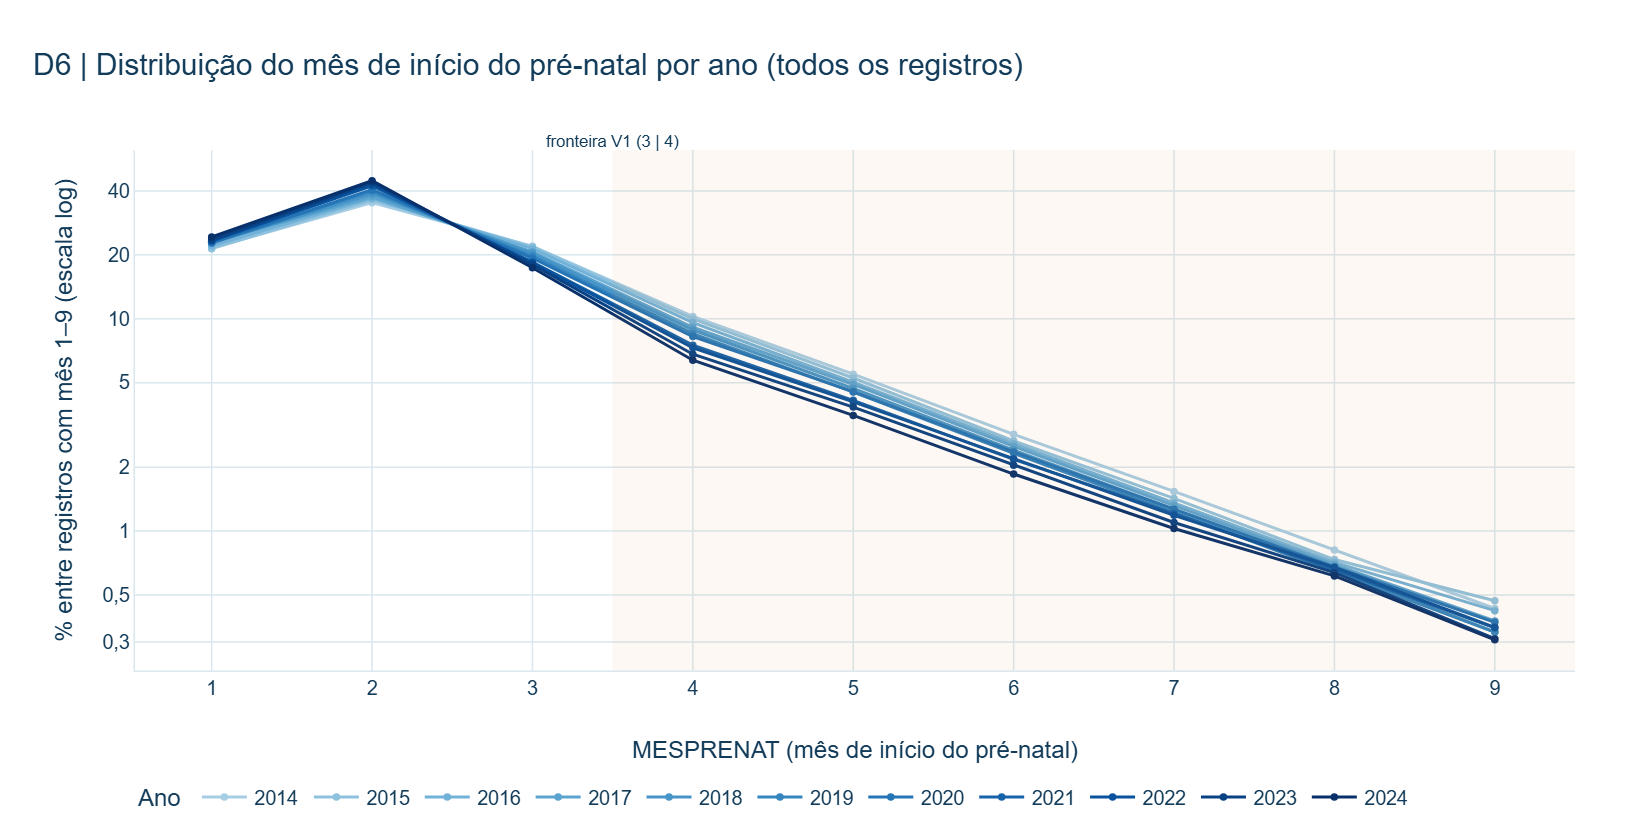

In [18]:
cores_anos = sample_colorscale('Blues', [0.35 + 0.65 * i / (len(ANOS) - 1) for i in range(len(ANOS))])
fig = go.Figure()
for cor, ano in zip(cores_anos, ANOS):
    s = dist[dist.ano == ano].set_index('mes').reindex(list(ap.MESES_VALIDOS))
    fig.add_scatter(x=list(range(1, 10)), y=100 * s.prop_meses_1_9, mode='lines+markers', name=str(ano),
                    line=dict(color=cor, width=2), marker=dict(size=5))
fig.add_vrect(x0=3.5, x1=9.5, fillcolor='#D9822B', opacity=0.06, line_width=0)
fig.add_annotation(x=3.5, y=1.04, yref='paper', text='fronteira V1 (3 | 4)', showarrow=False, font=dict(size=11))
fig.update_xaxes(title='MESPRENAT (mês de início do pré-natal)', dtick=1)
marcas = [0.3, 0.5, 1, 2, 5, 10, 20, 40]
fig.update_yaxes(title='% entre registros com mês 1–9 (escala log)', type='log', tickvals=marcas,
                 ticktext=[f'{v:g}'.replace('.', ',') for v in marcas], minor=dict(showgrid=False))
fig.update_layout(legend_title_text='Ano')
mostrar(fig, 'D6 | Distribuição do mês de início do pré-natal por ano (todos os registros)', 'fig6_d6_distribuicao_mesprenat')

**Leitura D6 (descritiva).**

- **O mês 2 é a moda e cresce.** Passa de 35,2% (2014) para 44,7% (2024) dos meses 1–9; o mês 3 cai de 21,9% para 17,4%, e o mês 4, de 10,3% para 6,4%.
- **Sem acúmulo no mês 3.** A razão de vizinhança do mês 3 é **menor que 1** e decrescente (0,97 → 0,68). O acúmulo relativo está no mês 2 (vizinhança 1,62 → 2,15).
- **Fronteira 3/4.** A razão 3/4 sobe de 2,14 para 2,73, sobretudo porque o mês 4 encolhe. O salto 3→4 é estável, entre 11,0 e 11,9 pp. Entre UFs, a razão 3/4 varia de 1,4 a 3,8.
- **Processo de mensuração.** `TPMETESTIM=8` nunca aparece sem DUM e cobre quase todos os registros com DUM (15,66 milhões; só 126 registros com DUM têm método vazio). Na prática, 8 funciona como "IG calculada pela DUM", um código operacional não documentado. Com DUM presente, `SEMAGESTAC` está preenchida em todos os registros, exceto 133. Sem DUM, a IG vem de exame físico (5,67 milhões), outro método (6,09 milhões) ou método ignorado (2,39 milhões). A razão 3/4 é um pouco maior com DUM (2,87 contra 2,60 em 2024).

Nada disso é interpretado como manipulação ou efeito. A fronteira 3/4 não mostra descontinuidade que justifique tratá-la como artefato.

## 13. D7 — população potencialmente sujeita ao problema temporal (A/B/C)

In [19]:
with cronometro('D7'):
    d7 = ap.d7_tabelas(cubos['ig_uf'], cubos['semanas'], cubos['perfil_categorico'], cubos['perfil_numerico'])
    salvar(d7['resumo'], 'populacoes_candidatas_pre_v2', 'Controles mantidos/excluídos, frações e M1 por alternativa',
           'ano x alternativa', 'ano, alternativa')
    salvar(d7['idade_gestacional'], 'd7_idade_gestacional_controles', 'Faixa de IG dos controles mantidos',
           'ano x alternativa x faixa', 'ano, alternativa, faixa_ig')
    salvar(d7['mesprenat'], 'd7_mesprenat_controles', 'MESPRENAT dos controles mantidos', 'ano x alternativa x mês',
           'ano, alternativa, mes')
    salvar(d7['controle_mes_ig'], 'd7_controle_v1_mes_ig', 'Controle V1 por mês e faixa de IG', 'ano x mês x faixa',
           'ano, mes, faixa_ig')
    salvar(d7['perfil'], 'd7_perfil_controles', 'Perfil X/Y descritivo dos controles mantidos (sem comparação com T=1)',
           'ano x alternativa x variável x nível', 'ano, alternativa, variavel, nivel')
r = d7['resumo']
cols = ['n_controle_v1', 'n_controles_mantidos', 'n_controles_excluidos', 'proporcao_mantida',
        'fracao_controle_4_5', 'fracao_controle_4_6', 'fracao_controle_6', 'fracao_controle_7_9']
display(r[r.alternativa == 'A_V1_4_9'].set_index('ano')[['n_controle_v1', 'fracao_controle_4_5', 'fracao_controle_4_6',
                                                         'fracao_controle_6', 'fracao_controle_7_9']])
display(r[r.ano == '2014-2024'].set_index('alternativa')[cols[1:4] + ['semana_maxima_afetada_L1', 'M1_L1',
                                                                      'semana_maxima_afetada_L2', 'M1_L2']])
print('M1 por ano (fração dos nascimentos ELEGIVEL com SEMAGESTAC válida estruturalmente afetados):')
display(r[r.ano != '2014-2024'].pivot(index='ano', columns='alternativa', values=['M1_L1', 'M1_L2']))
ig = d7['idade_gestacional'][d7['idade_gestacional'].ano == '2014-2024']
display((100 * ig.pivot(index='faixa_ig', columns='alternativa', values='prop')).reindex(ap.FAIXAS_IG).round(3))
cm = d7['controle_mes_ig'][d7['controle_mes_ig'].ano == '2014-2024']
print('Controle V1 2014–2024: % de cada mês dentro da faixa de IG')
display((100 * cm.pivot_table(index='faixa_ig', columns='mes', values='n', aggfunc='sum')
         .pipe(lambda t: t.div(t.sum(axis=1), axis=0))).reindex(ap.FAIXAS_IG).round(2))
pf = d7['perfil'][d7['perfil'].ano == '2014-2024']
print('Perfil descritivo dos controles mantidos (2014–2024):')
display(pf[pf.variavel == 'NUMERICO'].pivot(index='nivel', columns='alternativa', values='prop').round(4))
display((100 * pf[pf.variavel.isin(['ESCOLARIDADE_MAE', 'RACA_COR_MAE', 'PARIDADE_CAT'])]
         .pivot_table(index=['variavel', 'nivel'], columns='alternativa', values='prop')).round(2))

,n_controle_v1,fracao_controle_4_5,fracao_controle_4_6,fracao_controle_6,fracao_controle_7_9
ano,,,,,
2014,577127,0.7357,0.8694,0.1337,0.1306
2014-2024,5023057,0.7345,0.8684,0.1340,0.1316
2015,565595,0.7420,0.8717,0.1297,0.1283
2016,518310,0.7418,0.8731,0.1313,0.1269
2017,511767,0.7406,0.8733,0.1327,0.1267
2018,499451,0.7433,0.8758,0.1325,0.1242
2019,465593,0.7412,0.8741,0.1328,0.1259
2020,444287,0.7311,0.8666,0.1355,0.1334
2021,399172,0.7250,0.8612,0.1362,0.1388


,n_controles_mantidos,n_controles_excluidos,proporcao_mantida,semana_maxima_afetada_L1,M1_L1,semana_maxima_afetada_L2,M1_L2
alternativa,,,,,,,
A_V1_4_9,5023057,0,1.0000,31,0.0135,33,0.0269
B_4_6,4362208,660849,0.8684,19,0.0001,20,0.0002
C_4_5,3689347,1333710,0.7345,15,0.0000,16,0.0000


M1 por ano (fração dos nascimentos ELEGIVEL com SEMAGESTAC válida estruturalmente afetados):


M1_L1                  M1_L2              
alternativa A_V1_4_9  B_4_6  C_4_5 A_V1_4_9  B_4_6  C_4_5
ano                                                      
2014          0.0135 0.0001 0.0000   0.0276 0.0002 0.0000
2015          0.0133 0.0001 0.0000   0.0267 0.0002 0.0000
2016          0.0134 0.0001 0.0000   0.0271 0.0002 0.0000
2017          0.0134 0.0001 0.0000   0.0268 0.0001 0.0000
2018          0.0131 0.0001 0.0000   0.0262 0.0002 0.0000
2019          0.0131 0.0001 0.0000   0.0260 0.0001 0.0000
2020          0.0132 0.0001 0.0000   0.0264 0.0001 0.0000
2021          0.0134 0.0001 0.0000   0.0265 0.0001 0.0000
2022          0.0138 0.0001 0.0000   0.0274 0.0002 0.0000
2023          0.0139 0.0001 0.0000   0.0276 0.0001 0.0000
2024          0.0141 0.0001 0.0000   0.0277 0.0002 0.0000

alternativa,A_V1_4_9,B_4_6,C_4_5
faixa_ig,,,
<22,0.0360,0.0410,0.0480
22-26,0.2820,0.3240,0.3190
27-31,1.1830,1.2350,1.2250
32-36,10.0540,10.0530,9.9420
37-41,83.1590,83.2100,83.3730
>=42,3.6540,3.6540,3.6660
AUSENTE_OU_INVALIDA,1.6320,1.4830,1.4260


Controle V1 2014–2024: % de cada mês dentro da faixa de IG


mes,04,05,06,07,08,09
faixa_ig,,,,,,
<22,52.1400,46.9800,0.6700,0.1100,0.1100,NaN
22-26,51.5900,31.6100,16.6300,0.1100,0.0300,0.0300
27-31,47.5900,28.4100,14.6600,7.9600,1.3700,0.0200
32-36,46.2200,26.4100,14.2000,7.6300,4.2300,1.3100
37-41,48.0100,25.6300,13.2600,7.1200,3.8500,2.1300
>=42,48.1200,25.5700,13.1600,6.8800,3.7800,2.4900
AUSENTE_OU_INVALIDA,39.6400,24.5600,14.7000,9.3000,5.7100,6.1000


Perfil descritivo dos controles mantidos (2014–2024):


alternativa,A_V1_4_9,B_4_6,C_4_5
nivel,,,
idade_dp,6.9007,6.9041,6.9001
idade_media,25.3201,25.2897,25.3375
prevalencia_bpn,0.0803,0.0814,0.0807


alternativa                A_V1_4_9   B_4_6   C_4_5
variavel         nivel                             
ESCOLARIDADE_MAE 0           0.8400  0.7700  0.7100
                 1           6.3500  6.2000  6.0300
                 2          32.8300 32.8300 32.3400
                 3          48.8800 49.3000 49.7900
                 4           3.6500  3.6600  3.7300
                 5           6.1900  6.0600  6.2400
                 IGNORADO    1.2600  1.1800  1.1600
PARIDADE_CAT     0          32.6500 33.1100 33.6800
                 1          67.3500 66.8900 66.3200
RACA_COR_MAE     1          24.0100 24.0500 24.2800
                 2           7.4400  7.4000  7.3200
                 3           0.3700  0.3600  0.3700
                 4          63.4400 63.6000 63.5500
                 5           1.9400  1.8700  1.7800
                 IGNORADO    2.8000  2.7200  2.7000

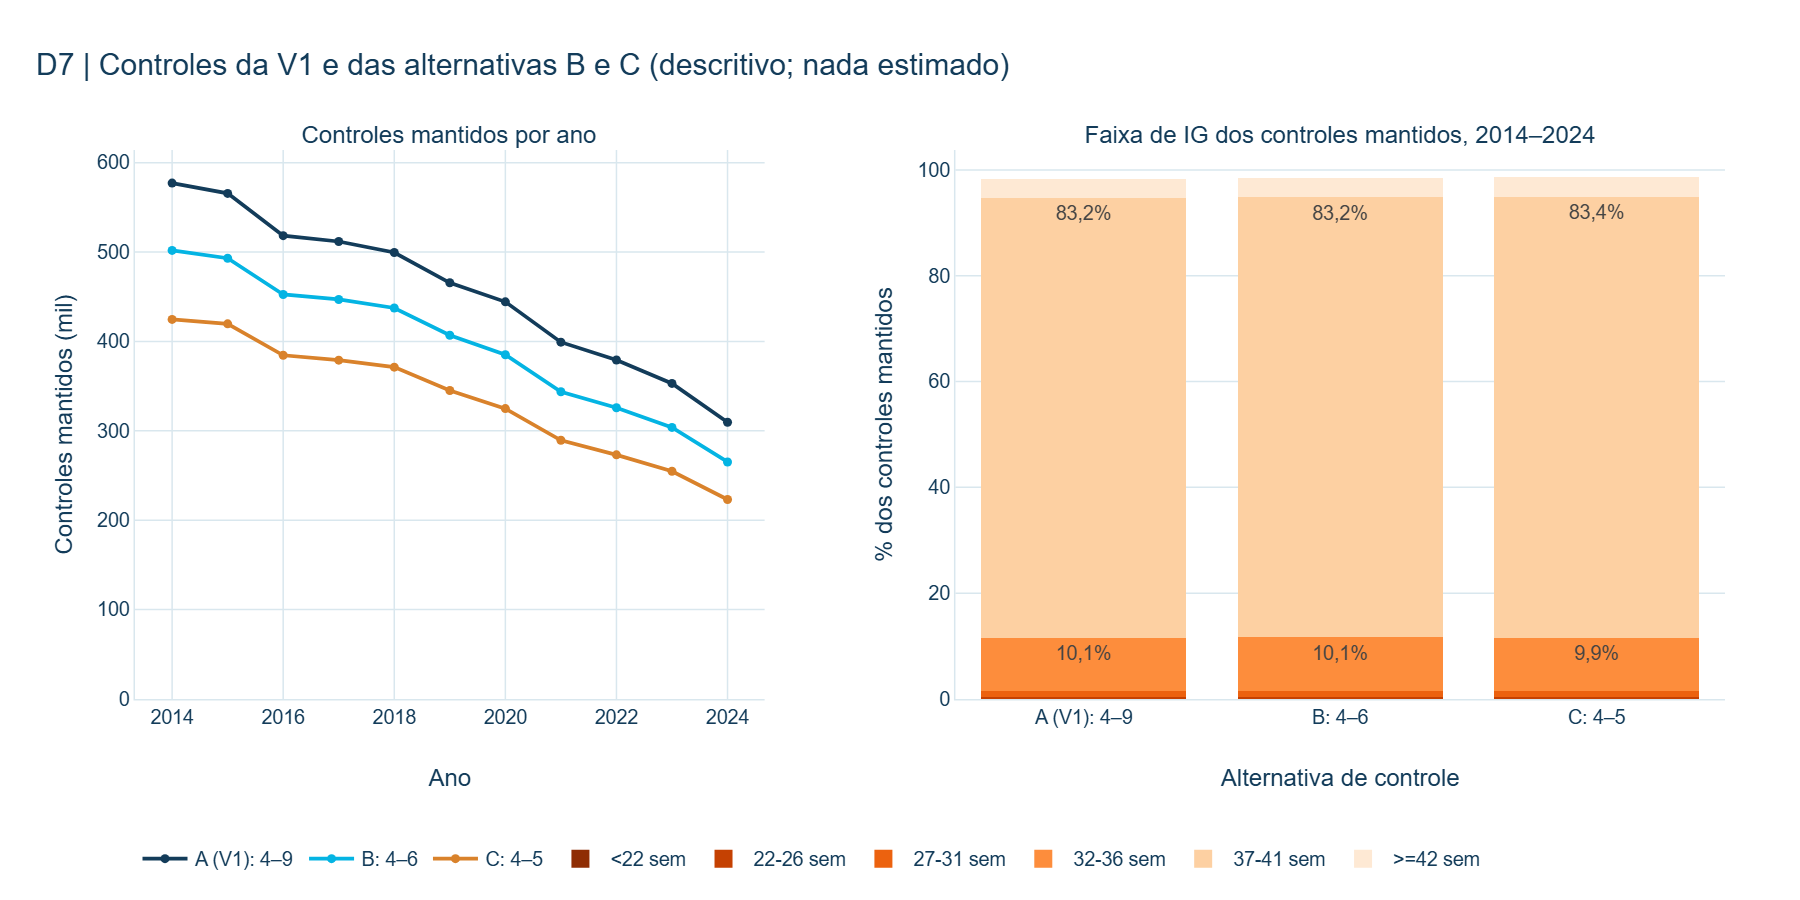

In [20]:
fig = make_subplots(rows=1, cols=2, column_widths=[0.45, 0.55], horizontal_spacing=0.12,
                    subplot_titles=('Controles mantidos por ano', 'Faixa de IG dos controles mantidos, 2014–2024'))
cores_alt = {'A_V1_4_9': CORES_IPT['AZUL_ESCURO'], 'B_4_6': CORES_IPT['CIANO'], 'C_4_5': '#D9822B'}
for alt in ap.ALTERNATIVAS_CONTROLE:
    s = r[(r.alternativa == alt) & (r.ano != '2014-2024')]
    fig.add_scatter(x=s.ano.astype(int), y=s.n_controles_mantidos / 1000, mode='lines+markers', name=ROTULO_ALT[alt],
                    line=dict(color=cores_alt[alt], width=2.5), row=1, col=1, legendgroup=alt)
faixas_ig = [f for f in ap.FAIXAS_IG if f != 'AUSENTE_OU_INVALIDA']
cores_faixa = sample_colorscale('Oranges', [0.95, 0.8, 0.65, 0.5, 0.25, 0.1])
for cor, faixa in zip(cores_faixa, faixas_ig):
    s = ig[ig.faixa_ig == faixa].set_index('alternativa').reindex(list(ap.ALTERNATIVAS_CONTROLE))
    fig.add_bar(x=[ROTULO_ALT[a] for a in s.index], y=100 * s.prop, name=f'{faixa} sem', marker_color=cor,
                row=1, col=2, text=[pct(v) if v >= 5 else '' for v in 100 * s.prop], textposition='inside')
fig.update_layout(barmode='stack', legend=dict(orientation='h', y=-0.25), uniformtext=dict(minsize=11, mode='hide'))
fig.update_yaxes(title_text='Controles mantidos (mil)', row=1, col=1, rangemode='tozero')
fig.update_xaxes(title_text='Ano', dtick=2, row=1, col=1)
fig.update_yaxes(title_text='% dos controles mantidos', row=1, col=2)
fig.update_xaxes(title_text='Alternativa de controle', row=1, col=2)
mostrar(fig, 'D7 | Controles da V1 e das alternativas B e C (descritivo; nada estimado)', 'fig7_d7_populacoes_abc', altura=600, largura=1200)

**Leitura D7 (descritiva; nada estimado).**

- **Composição do controle V1 (2014–2024, 5.023.057 registros).** 73,4% em 4–5, 13,4% no mês 6 (portanto 86,8% em 4–6) e **13,2% em 7–9**. A parcela de 7–9 oscila entre 12,4% e 14,3% e cresce desde 2020, enquanto o controle encolhe de 577 mil para 310 mil por ano.
- **B (4–6).** Mantém 4.362.208 controles (86,8%) e exclui 660.849.
- **C (4–5).** Mantém 3.689.347 (73,4%) e exclui 1.333.710.
- **Métrica estrutural M1.** Com A, 1,35% (L1) ou 2,69% (L2) dos nascimentos com IG válida estão abaixo da duração necessária para alcançar o último mês de controle (393.831 nascimentos em L1). Com B, 0,007% e 0,015% (2.115 e 4.456 nascimentos). Com C, um único nascimento (15 semanas, 2014).
- **A região afetada é pequena em volume.** A distribuição de IG dos controles mantidos quase não muda entre A, B e C (32–36 semanas: 10,05%, 10,05% e 9,94%), porque os estratos afetados (gestações abaixo de ~32 semanas) são poucos. Dentro deles, porém, a composição por mês muda radicalmente: em 22–26 semanas, 7–9 são 0,17% do controle, contra 13,1% em 37–41.
- **O perfil X/Y bruto dos controles mantidos é quase idêntico** (idade média 25,3 anos; BPN 8,0%–8,1%; escolaridade semelhante). Não há comparação com T=1.

O ganho de C sobre B na métrica estrutural é marginal (2.115 → 1 nascimento em L1) e custa 672.861 controles adicionais.

## 14. D8 — KOTELCHUCK (códigos não confirmados documentalmente)

In [21]:
with cronometro('D8'):
    d8 = ap.d8_tabelas(cubos['kotelchuck'])
    salvar(d8['x_consprenat'], 'kotelchuck_x_consprenat', 'KOTELCHUCK x categoria de CONSPRENAT',
           'população x ano x KOTELCHUCK x CONSPRENAT', 'populacao, ano, kotelchuck, consprenat')
    salvar(d8['x_mesprenat'], 'kotelchuck_x_mesprenat', 'KOTELCHUCK x grupo de MESPRENAT',
           'população x ano x KOTELCHUCK x grupo', 'populacao, ano, kotelchuck, grupo_mesprenat')
kc = d8['x_consprenat'][d8['x_consprenat'].populacao == 'ELEGIVEL']
km = d8['x_mesprenat'][d8['x_mesprenat'].populacao == 'ELEGIVEL']
tot_kc = kc.groupby(['kotelchuck', 'consprenat']).n.sum().unstack(fill_value=0)
tot_km = km.groupby(['kotelchuck', 'grupo_mesprenat']).n.sum().unstack(fill_value=0)
print('ELEGIVEL 2014–2024: KOTELCHUCK x CONSPRENAT (N)')
display(tot_kc.reindex(columns=[c for c in ap.CATEGORIAS_CONSPRENAT if c in tot_kc.columns]))
print('ELEGIVEL 2014–2024: KOTELCHUCK x grupo de MESPRENAT (N)')
display(tot_km.reindex(columns=[c for c in ap.GRUPOS_D3 if c in tot_km.columns]))
print('Distribuição anual de KOTELCHUCK (% ELEGIVEL):')
display((100 * kc.groupby(['ano', 'kotelchuck']).n.sum().unstack(fill_value=0).pipe(lambda t: t.div(t.sum(axis=1), axis=0))).round(2))
zero_k = kc[kc.consprenat == '0'].pivot_table(index='ano', columns='kotelchuck', values='prop_dentro_consprenat', fill_value=0)
print('Entre CONSPRENAT=0: % por código KOTELCHUCK, por ano')
display((100 * zero_k).round(2))

ELEGIVEL 2014–2024: KOTELCHUCK x CONSPRENAT (N)


consprenat,0,01-03,04-06,07-98,99,VAZIO
kotelchuck,,,,,,
1,174232,0,0,0,0,0
2,0,1234111,2129966,1880144,3828,17109
3,0,301412,1715623,0,0,0
4,0,0,2076061,0,0,0
5,0,0,0,18763057,0,0
9,0,107981,231110,445899,133836,515143


ELEGIVEL 2014–2024: KOTELCHUCK x grupo de MESPRENAT (N)


grupo_mesprenat,1-3,4-5,6,7-9,99,VAZIO,OUTRO_INVALIDO
kotelchuck,,,,,,,
1,7129,1126,352,1942,83805,79875,3
2,242948,3688221,672509,658907,0,0,2573
3,2017035,0,0,0,0,0,0
4,2076061,0,0,0,0,0,0
5,18763057,0,0,0,0,0,0
9,64924,0,0,0,649738,719307,0


Distribuição anual de KOTELCHUCK (% ELEGIVEL):


kotelchuck,1,2,3,4,5,9
ano,,,,,,
2014,0.5800,20.7300,7.5400,8.1000,55.9000,7.1500
2015,0.5300,19.9700,7.3300,7.9200,57.6800,6.5600
2016,0.5500,19.3600,7.2700,7.7400,59.4700,5.6100
2017,0.5800,18.7400,7.1600,7.2900,61.0800,5.1500
2018,0.6200,18.1500,6.9100,7.1300,62.7800,4.4200
2019,0.5800,17.5000,6.6000,6.7900,64.0100,4.5200
2020,0.6300,17.6300,7.3300,6.9000,63.0500,4.4600
2021,0.6100,16.1400,6.6900,6.6200,65.2900,4.6600
2022,0.6100,16.0000,6.3000,6.3400,67.1000,3.6500


Entre CONSPRENAT=0: % por código KOTELCHUCK, por ano


kotelchuck,1
ano,
2014,100.0000
2015,100.0000
2016,100.0000
2017,100.0000
2018,100.0000
2019,100.0000
2020,100.0000
2021,100.0000
2022,100.0000


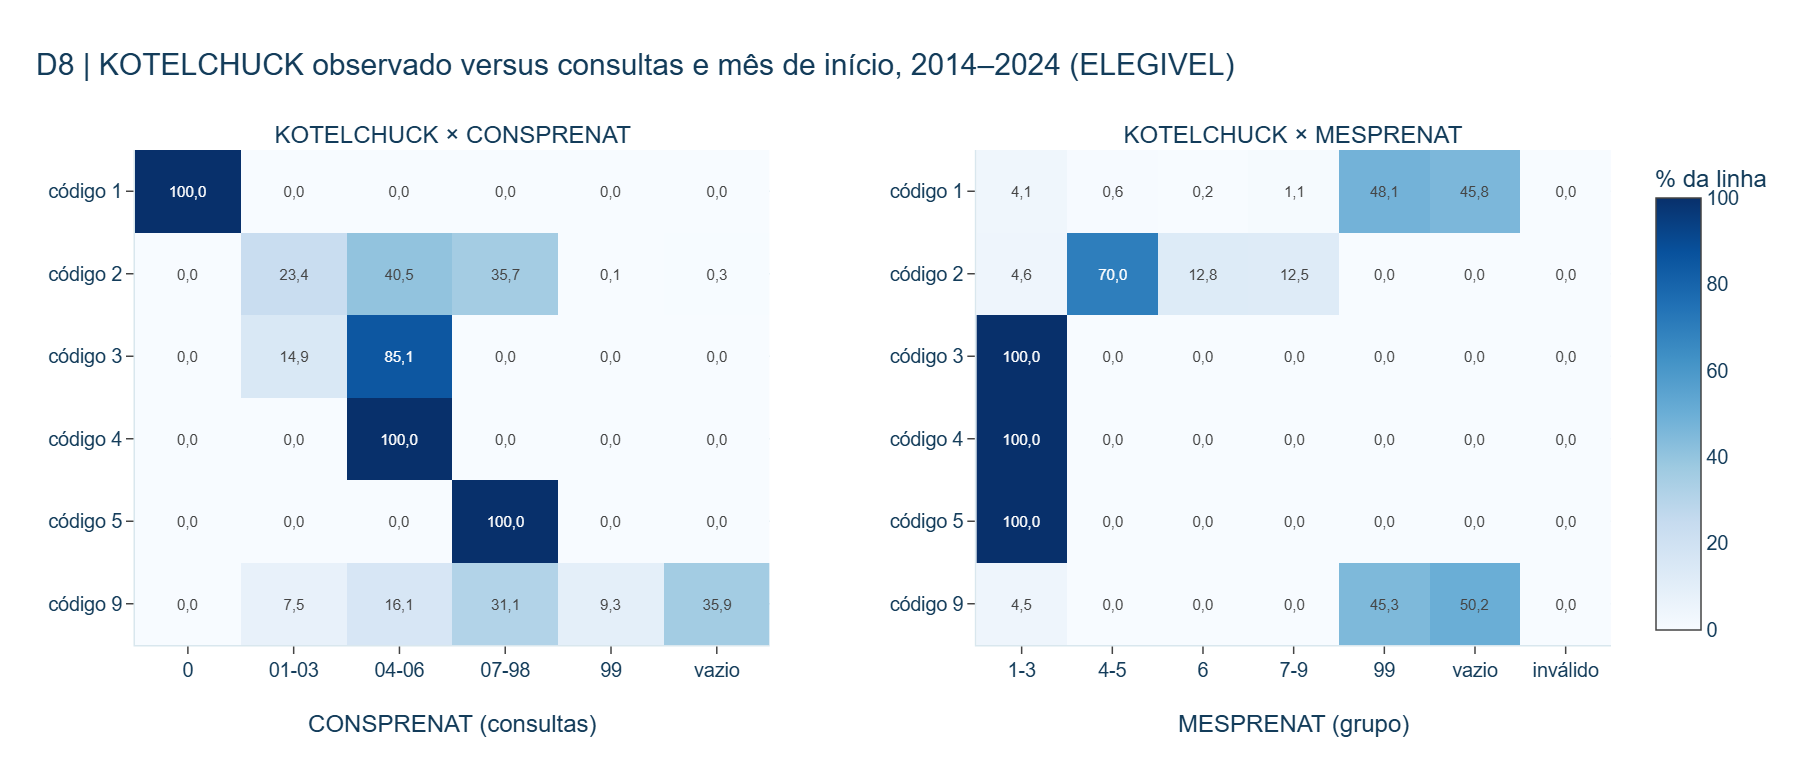

In [22]:
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.14,
                    subplot_titles=('KOTELCHUCK × CONSPRENAT', 'KOTELCHUCK × MESPRENAT'))
for col, tabela, ordem in ((1, tot_kc, ap.CATEGORIAS_CONSPRENAT), (2, tot_km, ap.GRUPOS_D3)):
    t = tabela.reindex(columns=[c for c in ordem if c in tabela.columns])
    p = 100 * t.div(t.sum(axis=1), axis=0)
    rotulos_x = {'OUTRO_INVALIDO': 'inválido', 'VAZIO': 'vazio'}
    fig.add_heatmap(z=p.to_numpy(), x=[rotulos_x.get(str(c), str(c)) for c in p.columns], y=[f'código {k}' for k in p.index],
                    colorscale='Blues', zmin=0, zmax=100, showscale=(col == 2),
                    text=np.vectorize(lambda v: f'{v:.1f}'.replace('.', ','))(p.to_numpy()), texttemplate='%{text}',
                    textfont=dict(size=10), colorbar=dict(title='% da linha'), row=1, col=col)
fig.update_xaxes(title_text='CONSPRENAT (consultas)', type='category', row=1, col=1)
fig.update_xaxes(title_text='MESPRENAT (grupo)', type='category', tickangle=0, row=1, col=2)
fig.update_xaxes(tickangle=0, row=1, col=1)
fig.update_yaxes(autorange='reversed')
mostrar(fig, 'D8 | KOTELCHUCK observado versus consultas e mês de início, 2014–2024 (ELEGIVEL)', 'fig8_d8_kotelchuck', altura=520, largura=1200)

**Leitura D8 (empírica; códigos sem definição oficial confirmada).**

O campo se comporta como índice **derivado** de `MESPRENAT` e `CONSPRENAT`, nos padrões de um índice de Kotelchuck modificado:

- **código 1** coincide com `CONSPRENAT=0` nas duas direções, em todos os anos;
- **códigos 3, 4 e 5** só ocorrem com início em 1–3, com 1–6, 4–6 e ≥ 7 consultas, respectivamente;
- **código 2** reúne início em 4–9 e início precoce com poucas consultas;
- **código 9** reúne mês ou consultas desconhecidos.

A distribuição muda no tempo: o código 5 sobe de 55,9% para 71,6%, o 9 cai de 7,2% para 3,0% e o 1 fica estável (~0,6%).

Por ser função dos mesmos dois campos, `KOTELCHUCK` **não acrescenta informação independente** para distinguir "nunca iniciou" de "início desconhecido". Não entra em X e não substitui `MESPRENAT`.

## 15. Aplicação mecânica dos gates G1–G7

As funções de `src.auditoria_pre_v2` aplicam literalmente os critérios da seção 5. `C1_documental` vem da seção 3 (Manual 2022, campo 33).

In [23]:
with cronometro('gates'):
    gates = {
        'G1': ap.avaliar_g1(d3['consprenat_zero'], d3['longa'], semantica_oficial=True),
        'G2': ap.avaliar_g2(d2['matriz'], ap.codigos_fora_dominio_mesprenat(cubos['ig_uf'])),
        'G3': ap.avaliar_g3(d4['smd']),
        'G4': ap.avaliar_g4(d7['resumo'], d1['padrao_truncamento']),
        'G5': ap.avaliar_g5(d7['resumo']),
        'G6': ap.avaliar_g6(d7['resumo']),
    }
    gates['G7'] = ap.avaliar_g7(gates)
assert ap.hash_criterios() == json.loads(arquivo_criterios.read_text(encoding='utf-8'))['hash_criterios']
resumo_gates = pd.DataFrame([{'gate': g, 'status': v['status'], 'pergunta': ap.CRITERIOS_GATES[g]['pergunta']} for g, v in gates.items()])
with pd.option_context('display.max_colwidth', 200):
    display(resumo_gates)
for g in ('G1', 'G2', 'G3', 'G5', 'G6', 'G7'):
    detalhe = {k: v for k, v in gates[g].items() if k not in ('M1', 'pior_por_grupo_variavel', 'uf_anos_divergentes')}
    print(g, json.dumps(detalhe, ensure_ascii=False, default=str)[:1500])
print('UF-anos divergentes em G1 (até 15):', gates['G1']['uf_anos_divergentes'][:15])
(pasta / 'gates_pre_v2_resultados.json').write_text(json.dumps(
    {'hash_criterios': ap.hash_criterios(), 'avaliado_em': datetime.now().isoformat(timespec='seconds'),
     'gates': gates, 'NENHUMA_NOVA_ESTIMATIVA_CAUSAL': True, 'V1_PRESERVADA': True, 'V2_NAO_ESCOLHIDA': True},
    ensure_ascii=False, indent=2, default=str) + '\n', encoding='utf-8')
saidas['gates_pre_v2_resultados.json'] = {'descricao': 'Status e evidência de G1-G7', 'granularidade': 'gate',
                                          'chave': 'gate', 'linhas': 7}

,gate,status,pergunta
0,G1,SINALIZADO,A codificação de 'sem pré-natal' é suficientemente estável para permitir landmark?
1,G2,SINALIZADO,MESPRENAT apresenta inconsistências temporais materiais?
2,G3,SINALIZADO,O missing de MESPRENAT parece diferencial por Y ou X?
3,G4,SINALIZADO,Qual parcela do controle V1 está em meses particularmente vulneráveis ao truncamento?
4,G5,APROVADO,A alternativa 4-6 reduz substancialmente a região estruturalmente problemática?
5,G6,APROVADO,A alternativa 4-5 reduz ainda mais?
6,G7,SINALIZADO,"Há evidência empírica suficiente para levar B, C ou D à avaliação metodológica?"


G1 {"status": "SINALIZADO", "C1_documental": true, "C2_ignorado_distinto": true, "C3_contradicao_minoritaria": true, "C4_estabilidade_temporal": false, "C5_estabilidade_uf": false, "fracao_contraditoria_por_ano": {"2014": 0.06231806570427137, "2015": 0.05974541034990085, "2016": 0.058715234400683804, "2017": 0.05445243025947131, "2018": 0.05407239819004525, "2019": 0.057927205428747686, "2020": 0.05162591977213387, "2021": 0.05570977917981072, "2022": 0.06420630221695942, "2023": 0.0736366090712743, "2024": 0.07864005912786401}, "categoria_dominante_por_ano": {"2014": "VAZIO", "2015": "VAZIO", "2016": "VAZIO", "2017": "VAZIO", "2018": "99", "2019": "VAZIO", "2020": "99", "2021": "99", "2022": "99", "2023": "99", "2024": "99"}, "n_uf_anos_avaliados": 261, "n_uf_anos_divergentes": 113}
G2 {"status": "SINALIZADO", "n_potencialmente_incompativel_L1_ou_tolerancia": 38, "n_potencialmente_incompativel_mesmo_com_tolerancia": 12, "n_potencialmente_incompativel_somente_L2": 28, "n_total_avaliado

**Leitura dos gates (aplicação mecânica das regras pré-registradas).**

| Gate | Status | Evidência decisiva |
| --- | --- | --- |
| G1 | `SINALIZADO` | C1–C3 verdadeiros (semântica oficial de `CONSPRENAT=0`; categoria de desconhecido distinta; contradição com mês válido de 5,2%–7,9%). C4 falso: a categoria dominante alterna entre vazio e `99`. C5 falso: 113 de 261 UF-anos divergem da nacional. |
| G2 | `SINALIZADO` | 38 registros potencialmente incompatíveis em L1 (12 mesmo com tolerância) e código `10` em 2014. A maior fração em um mês-ano é 0,033%, longe do limite de bloqueio de 50%. |
| G3 | `SINALIZADO` | Diferencial por Y (BPN, todos os anos e grupos) e por X (615 de 1.265 comparações com |SMD| ≥ 0,10). |
| G4 | `SINALIZADO` | 13,2% do controle V1 em 7–9 (12,4%–14,3%). P1 falhou nos 11 anos (não monotônico acima de 27 semanas); a evidência auxiliar não decide o gate. |
| G5 | `APROVADO` | O último mês de B começa antes de 22 semanas em L1 (20) e L2 (21,7), e M1(B) < M1(A) em todos os anos, nas duas leituras. |
| G6 | `APROVADO` | M1(C) < M1(B) em todos os anos, nas duas leituras. O ganho absoluto é marginal (≈0,007 pp) e custa 672.861 controles adicionais; o custo não entra na regra. |
| G7 | `SINALIZADO` | B = pior(G5, G2, G3) = `SINALIZADO`; C = `SINALIZADO`; D = `PENDENTE` (G1 sinalizado). |

**G7 não escolhe V2.** Nenhum AIPW de B, C ou D foi calculado ou consultado.

## 16. Desempenho, memória e volume dos artefatos

In [24]:
tempo_total = time.perf_counter() - INICIO_NOTEBOOK
cubo_t = tempos_ano.drop(columns=['ano']).sum()
print(f'Tempo total do notebook até aqui: {tempo_total:.1f} s | agregação DuckDB: {tempo_agregacao:.1f} s')
display(tempos_ano.set_index('ano').round(2))
uso = pd.DataFrame([{'etapa': k, 'segundos_2014_2024': v, 'diagnosticos_atendidos': ', '.join(ap.DIAGNOSTICOS_POR_CUBO.get(k, ('todos',)))}
                    for k, v in cubo_t.items() if k != 'total_ano'])
display(uso.round(2))
display(pd.Series(tempos_diag, name='segundos_pos_processamento').round(3).to_frame())
display(memoria_ano.set_index('ano').round(0))
tamanhos = pd.DataFrame([{'arquivo': p.relative_to(pasta).as_posix(), 'bytes': p.stat().st_size}
                         for p in sorted(pasta.rglob('*')) if p.is_file()])
print(f"Artefatos: {len(tamanhos)} arquivos, {tamanhos.bytes.sum() / 2**20:.2f} MiB")
display(tamanhos)

Tempo total do notebook até aqui: 69.7 s | agregação DuckDB: 28.9 s


,leitura_derivacao,ig_uf,semanas,gestacao,consprenat,processo,kotelchuck,perfil_categorico,perfil_numerico,total_ano
ano,,,,,,,,,,
2014,1.1200,0.1400,0.0800,0.0900,0.0900,0.1000,0.0800,0.4900,0.0500,2.4200
2015,1.2200,0.1100,0.0900,0.1000,0.0800,0.0900,0.0700,0.4600,0.0400,2.4900
2016,1.1000,0.0900,0.0700,0.0900,0.0800,0.0900,0.0700,0.4800,0.0500,2.2900
2017,1.1000,0.1000,0.0800,0.0900,0.0800,0.1000,0.0700,0.5000,0.0600,2.3500
2018,1.2100,0.1100,0.0800,0.1000,0.0900,0.1100,0.0800,0.5700,0.0600,2.6900
2019,1.3500,0.1200,0.0900,0.1000,0.0900,0.1100,0.0800,0.5800,0.0600,2.8400
2020,1.2900,0.1100,0.0900,0.1000,0.0900,0.1100,0.0800,0.5800,0.0600,2.7000
2021,1.2900,0.1200,0.1000,0.1100,0.1300,0.1100,0.1000,0.6400,0.0700,2.9200
2022,1.2600,0.1300,0.0900,0.1100,0.0900,0.1100,0.0800,0.5800,0.0600,2.7600


,etapa,segundos_2014_2024,diagnosticos_atendidos
0,leitura_derivacao,13.3800,todos
1,ig_uf,1.3100,"D1, D5, D6, D7"
2,semanas,0.9600,"D2, D7"
3,gestacao,1.1500,D1
4,consprenat,1.0200,D3
5,processo,1.1600,D6
6,kotelchuck,0.9000,D8
7,perfil_categorico,6.1000,"D4, D7"
8,perfil_numerico,0.6200,"D4, D7"


,segundos_pos_processamento
D1,0.2940
D2,0.1150
D3,0.4380
D4,0.6880
D5,0.0900
D6,0.3640
D7,0.3360
D8,0.0650
gates,0.1480


,rss_mb,pico_mb
ano,,
2014,262.0000,842.0000
2015,271.0000,868.0000
2016,594.0000,868.0000
2017,725.0000,907.0000
2018,282.0000,934.0000
2019,282.0000,934.0000
2020,766.0000,934.0000
2021,287.0000,934.0000
2022,289.0000,934.0000


Artefatos: 39 arquivos, 6.87 MiB


,arquivo,bytes
0,criterios_gates_pre_v2.json,7322
1,d1_gestacao_oficial_x_faixa_semagestac.csv,3904
2,d1_mesprenat_gestacao_oficial.csv,44083
3,d1_mesprenat_idade_gestacional_brasil.csv,64000
4,d1_mesprenat_idade_gestacional_uf.csv,1069486
5,d1_padrao_truncamento.csv,2340
6,d2_consistencia_mesprenat_semagestac.csv,1070062
7,d2_resumo_status_por_mes.csv,9872
8,d3_consprenat0_mesprenat.csv,299517
9,d3_consprenat_mesprenat.csv,2022130


## 17. Integridade e manifesto

In [25]:
reservados_fim = impressoes_reservadas()
alterados = sorted(k for k in set(reservados_inicio) | set(reservados_fim) if reservados_inicio.get(k) != reservados_fim.get(k))
assert not alterados, f'Arquivos reservados alterados: {alterados}'
hash_parquets = {str(a): ap.sha256_arquivo(caminhos[a]) for a in ANOS}
git_status_fim = git('status', '--short', '--untracked-files=all')
novos = sorted(set(git_status_fim.splitlines()) - set(git_status_inicio.splitlines()))
print('Arquivos reservados inalterados:', len(reservados_fim))
print('Linhas novas no git status:', *novos, sep='\n  ')
fora_escopo = [l for l in novos if not any(s in l for s in ('outputs/temporal/pre_v2/', 'notebooks/09c_', 'src/auditoria_pre_v2.py',
                                                            'tests/test_auditoria_pre_v2.py'))]
assert not fora_escopo, f'Mudança fora do escopo: {fora_escopo}'

limitacoes = {
    'schema_pre_v2.csv': 'nomes comparados sem diferenciar caixa',
    'd1_': 'faixas descritivas, não meses oficiais; SEMAGESTAC com erro',
    'd2_': 'leituras mês-semana são convenções; nada é impossível',
    'd3_': 'não demonstra validade de CONSPRENAT=0',
    'd4_': 'SMD de seleção/missingness; não é balanceamento causal',
    'd5_': 'triagem de discrepância é convenção descritiva',
    'd6_': 'sem distribuição de referência verdadeira',
    'populacoes_candidatas': 'nenhum efeito estimado; M1 depende de L1/L2',
    'd7_': 'perfil bruto, sem comparação com T=1',
    'kotelchuck': 'códigos não confirmados documentalmente',
}
for nome, meta in saidas.items():
    meta['limitacao'] = next((v for k, v in limitacoes.items() if nome.startswith(k)), 'diagnóstico descritivo')
    meta['validacao'] = 'soma das agregações = registros do Parquet; população V1 = notebook 08'
    meta['proximo_passo'] = 'avaliação metodológica humana das formulações B, C e D antes de qualquer estimação'
    caminho = pasta / nome
    if caminho.exists():
        meta['bytes'] = caminho.stat().st_size
        meta['sha256'] = ap.sha256_arquivo(caminho)

manifesto = {
    'artefato': 'auditoria pré-V2 da temporalidade de MESPRENAT (notebook 09c)',
    'versao': ap.VERSAO_AUDITORIA, 'hash_criterios': ap.hash_criterios(),
    'git_branch': git_branch, 'git_head': git_head, 'executado_em': datetime.now().isoformat(timespec='seconds'),
    'python': sys.version.split()[0], 'duckdb': __import__('duckdb').__version__, 'pandas': pd.__version__,
    'anos': ANOS, 'registros_brutos': {str(k): int(v) for k, v in n_bruto.items()},
    'parquets_sha256': hash_parquets,
    'populacoes': {'BRUTA': 'todos os registros', 'ELEGIVEL': 'GRAVIDEZ=1 e PESO 500-6000 g',
                   'V1': 'ELEGIVEL e MESPRENAT 01-09 (idêntica ao notebook 08)'},
    'fontes_documentais': fontes_documentais,
    'gates': {g: v['status'] for g, v in gates.items()},
    'formulacoes_g7': gates['G7']['formulacoes'],
    'tempos_segundos': {'total_notebook': round(time.perf_counter() - INICIO_NOTEBOOK, 1),
                        'agregacao_duckdb': round(tempo_agregacao, 1),
                        'por_etapa_agregacao': {k: round(float(v), 2) for k, v in cubo_t.items()},
                        'pos_processamento_por_diagnostico': {k: round(v, 3) for k, v in tempos_diag.items()}},
    'memoria_mb': {'rss_max_medido': round(float(memoria_ano.rss_mb.max()), 0),
                   'pico_processo': round(float(memoria_ano.pico_mb.max()), 0)},
    'saidas': saidas,
    'arquivos_reservados_inalterados': len(reservados_fim),
    'NENHUMA_NOVA_ESTIMATIVA_CAUSAL': True, 'V1_PRESERVADA': True, 'V2_NAO_ESCOLHIDA': True,
    'microdados_salvos': False,
}
(pasta / 'manifesto_pre_v2.json').write_text(json.dumps(manifesto, ensure_ascii=False, indent=2, default=str) + '\n', encoding='utf-8')
print('Manifesto gravado. Gates:', manifesto['gates'])

Arquivos reservados inalterados: 801
Linhas novas no git status:


Manifesto gravado. Gates: {'G1': 'SINALIZADO', 'G2': 'SINALIZADO', 'G3': 'SINALIZADO', 'G4': 'SINALIZADO', 'G5': 'APROVADO', 'G6': 'APROVADO', 'G7': 'SINALIZADO'}


## 18. Conclusões, limitações e vereditos

**Formulações que podem seguir para discussão metodológica (com ressalvas):**

- **B (≤3 vs 4–6):** elimina praticamente toda a região estruturalmente vulnerável, mantendo 86,8% dos controles.
- **C (≤3 vs 4–5):** elimina o restante, que já é residual, ao custo de mais 13,4 pp dos controles.

As duas herdam as ressalvas de G2 (inconsistências raras) e G3 (ausência de dados diferencial em Y e X). As duas também redefinem o estimando: o contraste passa a ser entre início precoce e início moderadamente tardio. Isso precisa ser discutido antes de qualquer estimação.

**Permanece pendente:** D (*landmark*). A ausência de pré-natal tem semântica oficial (`CONSPRENAT=0`), mas a codificação conjunta com `MESPRENAT` é instável entre anos e UFs, 5%–8% dos casos informam mês válido, e a validade do zero não é demonstrável com estes dados. `KOTELCHUCK` não resolve, pois é derivado dos mesmos campos.

**Permanece preservada:** a V1, como contraste observacional padronizado na população selecionada. O diagnóstico reforça que ela não deve ser lida como efeito de uma intervenção bem definida de início precoce: 13,2% dos seus controles pertencem a meses cuja ocupação exige gestação longa.

**Validade de MESPRENAT.** Os dados mostram completude crescente (desconhecido de 7,6% para 3,4%) e consistência alta com a IG. Não mostram validade contra padrão-ouro, que segue sem estudo localizado pós-2011. Ausência de validação não é prova de invalidade.

**Limitações desta auditoria:**

- as leituras mês→semana (L1, L2) são convenções, não regras oficiais;
- `SEMAGESTAC` tem concordância moderada e mistura DUM e estimativa;
- os perfis são brutos;
- a triagem de UFs é convenção de leitura;
- os códigos de `KOTELCHUCK`, `99` e `TPMETESTIM=8` não têm definição oficial confirmada;
- tudo se restringe a nascidos vivos;
- P1 falhou como pré-registrada e foi mantida assim.

**Vereditos:** `AUDITORIA_PRE_V2_CONCLUIDA` · G1 = `SINALIZADO` · G2 = `SINALIZADO` · G3 = `SINALIZADO` · G4 = `SINALIZADO` · G5 = `APROVADO` · G6 = `APROVADO` · G7 = `SINALIZADO` · `NENHUMA_NOVA_ESTIMATIVA_CAUSAL` · `V1_PRESERVADA` · `V2_NAO_ESCOLHIDA`.